# Evolutionary search for new coding algorithms — runnable demo (iteration 7, claim N)

**Question.** Can an evolutionary *program search* make an 8B model write correct **out-of-catalogue** algorithms (algorithms that are not among the textbook solutions of a task) far more often per call than prompting alone? The search is FunSearch-style islands over a MAP-Elites archive, with an executable evaluator and a novelty critic built from 18,237 known solutions.

**Pre-registered prediction.** The search arm **S** produces distinct programs that pass the out-of-catalogue (OOC) screen at **≥ 10×** the per-call rate of **K**, the better of the two iteration-5 text knobs (EAP, BINT), on ≥ 2 tasks.

**Setup of the original run** (`method.py`, 13 stages):
- **Mutator:** Qwen3-8B (bf16, thinking off, vLLM, T = 1.0) on one RTX A4500.
- **Tasks:**
  - T2: weighted shortest path.
  - T03: k-th smallest.
  - A3: trapping rain water.
- **Evaluator:** a 3-stage sandbox: 8 quick cases → hidden suite → 10 seeded maximum-size stress inputs.
- **Novelty critic:** token 4-gram Jaccard similarity to the known-solution corpus.
- **Arms:**
  - S: the search.
  - NE: no evolution; same prompt, frozen seed parents.
  - I0: the instruction only.
  - EAP and BINT: the iteration-5 knobs.
  - B0: the neutral prompt.
  - L: a 235B mutator.
- **Size:** 13,100 decisive programs.

**Result: prediction NOT MET** (level a: R̂ = 3.83 / 6.65 / 0.91 on T2 / T03 / A3). Only T03 yields programs that were adjudicated *known outside the catalogue* (S 78 vs EAP 0). All of them are known techniques: value-range binary search, Fenwick trees, treaps and bucket select. **0 novel algorithms** were found.

**What this notebook runs.** It runs the CPU side of the method, using the original code, over 100 recorded T03 programs from the run; the computation takes under a minute on Colab. Every section checks its output against the published run:

| § | Original code | What it reproduces here |
|---|---|---|
| 1 | `method.py` constants | the pre-registered hypothesis, prediction, budget ladder and definitions |
| 2–3 | `src/common.py`, `src/inputs.py` | paths, hashing, the commitments hash chain, task objects |
| 4 | `src/sandbox.py`, `src/sandbox_runner.py`, unit tests U1 | the 3-stage sandboxed evaluator |
| 5 | `src/critic.py`, unit test U3 | the novelty critic (nearest-known similarity) |
| 6–7 | `src/labels.py`, `method.py stage_commit1` | the per-task screen threshold s\* and N per arm |
| 8 | `src/run.py` Evaluator, `src/finalize.py` | re-evaluating programs and applying the OOC screen |
| 9 | `src/search.py`, `src/prompts.py`, `src/run.py` | replaying the archive: the same parent picks and byte-identical prompts |
| 10 | `src/analysis.py`, unit test U5 | the exact rate-ratio tests and the verdict |

**What is replayed, not re-run.** Some stages need a GPU, paid APIs or vendored code from earlier iterations, so their recorded outputs are used instead:
- **GPU stages** (`calib`, `base`, `run`): Qwen3-8B on vLLM, about 1 GPU-hour.
- **OpenRouter stages:** the label-dispute judge, the adjudication judges and arm L.
- **Frozen runtime labellers:** vendored code from earlier iterations.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, rapidfuzz -- NOT on Colab, always install (versions pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
# Import blocks of method.py and of the src/ modules this notebook runs (common, sandbox, critic, labels, search,
# prompts, run, analysis). Python 3.12 evaluates their `str | None` annotations natively, so the modules'
# `from __future__ import annotations` line is not needed; argparse (the stage CLI) is replaced by notebook cells.
import ast
import builtins
import hashlib
import io
import json
import keyword
import math
import os
import random
import re
import resource
import shutil
import statistics
import subprocess
import sys
import time
import tokenize
import zlib
from collections import Counter, defaultdict
from concurrent.futures import Future, ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from loguru import logger
from scipy import sparse, stats

# notebook additions: tables and figures
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-7/experiment-37/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
MD = data["metadata"]                      # support data: tasks, seeds, calibration pool, corpus subset, published results
EXAMPLES = data["datasets"][0]["examples"] # 100 T03 programs generated in the run (one row each, as in data/rows_T03.jsonl)
print(data["datasets"][0]["dataset"], "-", len(EXAMPLES), "programs:", MD["examples_composition"])
print("by arm:", dict(Counter(e["arm"] for e in EXAMPLES)))
print("support data:", {k: len(v) for k, v in MD.items() if isinstance(v, (list, dict))})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
T03_generated_programs - 100 programs: {'search_round0': 48, 'curated': 52}
by arm: {'S': 73, 'NE': 5, 'I0': 6, 'EAP': 5, 'BINT': 5, 'B0': 3, 'L': 3}
support data: {'examples_composition': 2, 'tasks': 3, 'seeds': 3, 'search_seeds_T03': 6, 'calibration_rows': 510, 'corpus_subset': 108, 'search_prompt_log': 36, 'published': 14}


## Configuration

All demo-scale knobs live here. They are set to the **largest values the mini data supports**, and the whole notebook runs in about 30 s on 2 CPUs. Each comment gives the value used in the original run. The smallest setting that still produces every output is `N_EVAL_PROGRAMS = 2`, `N_SEARCH_ROUNDS = 1`, `N_BOOTSTRAP_REPS = 100`.

- **`N_EVAL_PROGRAMS`**: the number of the 100 example programs re-run through the sandbox and the critic.
- **`N_SEARCH_ROUNDS`**: the number of search rounds whose parent selection is re-drawn and checked against the run. The mini data holds the 48 children of round 0. Because the archive updates with a one-round lag, those children fix the parent picks of rounds 0–2, so the maximum here is 3.
- **`N_BOOTSTRAP_REPS`**: the number of island-bootstrap replicates. The run used 2,000.
- **`EVAL_WORKERS`**: the number of sandbox worker threads.
- **`GPU_HOURS`**: the GPU budget given to `stage_commit1`, which picks the size of the experiment (the budget ladder).

Going beyond these values, toward the run's 13,600 programs and 53 search rounds on T03, needs the GPU generation stages of `method.py`.

In [5]:
# ---- demo scale: the largest values the mini data supports (minimum: 2 / 1 / 100); the run's values in the comments
N_EVAL_PROGRAMS = 100     # example programs re-run through the sandbox + critic (mini data: 100; run: 13,600 programs)
N_SEARCH_ROUNDS = 3       # S rounds whose parent picks are re-drawn and checked (mini data: <= 3; run on T03: 53 rounds)
N_BOOTSTRAP_REPS = 2000   # island-bootstrap replicates of S's level-a rate on T03 (run: 2,000)
EVAL_WORKERS = 2          # sandbox worker threads (run: EVAL_WORKERS = 8 on 11 vCPUs)
GPU_HOURS = 2.0           # `method.py --stage commit1 --gpu-hours 2.0`: GPU budget that sets the ladder level
WORKDIR = Path("aii_demo_workspace")   # stands in for the artifact folder (inputs/, data/, predictions/, results/)

## 1. The pre-registered claim (`method.py`)

`method.py` is a stage CLI: `uv run method.py --stage {inputs, corpus, tests, commit0, calib, commit1, base, run, L, label, adjudicate, analyse, outputs}`. Its module-level constants are the pre-registration. `stage_commit0` hash-committed them to `commitments.log` before any GPU sample:
- the hypothesis and the prediction;
- the budget ladder (calls per arm, with drop order and floors);
- the operational definitions (*call*, *correct*, *OOC screen*, *distinct*, the two levels);
- the statistical tests;
- the judge models and the judge prompt;
- the 10-control judge gate.

The code below is copied unchanged.

In [6]:
HYPOTHESIS = (
    "Claim N (iteration 7, secondary family): a FunSearch / MAP-Elites program search with Qwen3-8B (bf16, thinking "
    "off, vLLM, T 1.0) as the mutator, hidden tests plus fresh randomised stress tests as the evaluator, and a novelty "
    "critic built against the 18,237 known solutions of art_j3Rm_lr2nzR6 produces correct out-of-catalogue programs "
    "at a much higher rate per call than the best single-sample text knobs of iteration 5, on memorised "
    "LeetCode-style tasks with one 8B mutator.")
PREDICTION = ("S >= 10x K on >= 2 tasks: per task the point estimate R_hat = (X_S/N_S)/(X_K/N_K) >= 10 and the exact "
              "conditional Poisson one-sided 95% lower bound LB95 on R above 1, at level a (distinct OOC_screen "
              "programs), K = the better of EAP and BINT per task (max rule). With 2 tasks run, MET needs both.")
LADDER = {
    "level0": {"T2": {"S": 1500, "EAP": 750, "BINT": 750, "NE": 500, "I0": 500, "B0": 200},
               "T03": {"S": 1500, "EAP": 750, "BINT": 750, "NE": 500, "I0": 500, "B0": 200}},
    "level1": {"A3": {"S": 1000, "EAP": 500, "BINT": 500, "NE": 300, "I0": 300, "B0": 100}},
    "level2": "raise S on T03 then T2 in +1000 steps up to 4000 while time allows; K arms >= S/2",
    "level3": "reachability (prompt_logprobs teacher forcing) - optional",
    "level4": "large mutator arm L on T03 via OpenRouter, 500 children, <= USD 1.0 - optional, concurrent",
    "level5": "plan noise - first dropped",
    "floors": {"S": 1000, "EAP": 400, "BINT": 400, "NE": 300, "I0": 300, "B0": 100},
    "drop_order": ["plan_noise", "L (only if OpenRouter binds)", "reachability", "A3", "I0->300,B0->100",
                   "K arms->500", "S->1500->1000 on T2/T03"],
}
DEFINITIONS = {
    "call": "one generated child program (one completion); EAP/BINT count only code-writing calls, their stage-1 GPU "
            "time is charged to their GPU-seconds",
    "correct": "valid (AST pre-screen) AND stage 1 (8 quick cases) AND stage 2 (full hidden suite) AND stage 3 (10 "
               "seeded max-size stress inputs vs the fastest reference)",
    "OOC_screen": "correct AND (final label == 'other' OR nearest-known Jaccard s < s*_task), s*_task = 5th "
                  "percentile of nearest-known similarities of correct forced catalogue programs (label == Y) and "
                  "the references",
    "distinct": "within an arm in call order: identical normalised-token hash merges, then Jaccard >= 0.9 to an earlier "
                "program collapses into it",
    "idea_cluster": "pooled over arms, within each cell (runtime label, DS-signature): single-linkage components at "
                    "Jaccard >= 0.5; after adjudication clusters whose judges named the same algorithm merge",
    "level_a": "distinct OOC_screen programs", "level_b": "distinct adjudicated KNOWN OUTSIDE CATALOGUE + NOVEL",
    "cell": "(runtime label, DS-signature = first 3 of heap, deque_or_queue, sort, bisect, recursion, dict_or_counter, "
            "set, matrix_2d, stack_list, bitops, random, custom_class)",
    "novelty": "nu = 1 - s, s = max token-4-gram Jaccard to corpus + catalogue references (self-match of a seed excluded)",
}
TESTS = {
    "primary": "exact conditional binomial test of two Poisson rates; LB95 from the one-sided Clopper-Pearson bound; "
               "two-sided 95% CI; Holm across tasks",
    "verdict": "STRONG LB95>=10; MET R_hat>=10 & LB95>1; UNRESOLVED R_hat>=10 & LB95<=1; NOT MET R_hat<10; "
               "NOT ESTIMABLE X_S=X_K=0; overall MET if >=2 tasks MET/STRONG",
    "secondary": ["S vs NE", "S vs I0", "NE vs I0", "I0 vs K", "K vs B0", "L vs S (first 500 calls, T03)"],
    "matched_effort": "rarefaction/Chao-1 extrapolation of idea-cluster richness of i.i.d. arms to N_S (trusted to 2x N)",
    "robustness": "island-cluster bootstrap (2,000 reps) of S's rate; arm-shuffle placebo; seeds-as-children check",
    "zero": "rule of three 3/n",
}
JUDGES = {"pair": ["mistralai/mistral-medium-3.1", "moonshotai/kimi-k2-0905"],
          "replacements": ["google/gemini-2.5-flash", "deepseek/deepseek-chat-v3.1", "openai/gpt-4.1-mini"],
          "third": "deepseek/deepseek-chat-v3.1", "temperature": 0, "gate": ">= 9 of 10 controls",
          "label_dispute_judge": "google/gemini-2.5-flash-lite",
          "L_mutator": "qwen/qwen3-235b-a22b-2507", "L_fallback": "qwen/qwen3-coder"}
JUDGE_PROMPT = (
    "You are an expert in algorithms. Decide whether the program below implements a NEW algorithm for a known task.\n\n"
    "TASK\n{spec}\n\nCATALOGUE (the standard known algorithms for this task)\n{catalogue}\n\n"
    "PROGRAM UNDER REVIEW (comments and docstrings removed)\n```python\n{code}\n```\n\n"
    "NEAREST KNOWN SOLUTIONS from a corpus of 18,237 published code solutions (for comparison)\n{nearest}\n\n"
    "SANDBOXED STRESS RESULTS of the program (inputs at three sizes; runtime ratio to the fastest catalogue "
    "reference; log-log slope of runtime against size)\n{stress}\n\n"
    "Classify the program's core algorithm into exactly one class:\n"
    "- NOVEL ALGORITHM: a correct general algorithm whose core mechanism is not in the catalogue and that you cannot "
    "identify as any known published algorithm or textbook technique.\n"
    "- KNOWN OUTSIDE CATALOGUE: a correct general algorithm that is a known, nameable algorithm or textbook technique "
    "not in the catalogue (name it).\n"
    "- CATALOGUE VARIANT: an implementation, restyling or minor modification of a catalogue algorithm (name which).\n"
    "- DEGENERATE: hard-coded or special-cased answers, wrong in general, or brute force that passes only because "
    "the tests are small.\n\n"
    "Answer with JSON only: {{\"class\": \"NOVEL ALGORITHM|KNOWN OUTSIDE CATALOGUE|CATALOGUE VARIANT|DEGENERATE\", "
    "\"named_algorithm\": \"...\", \"core_idea\": \"<one sentence>\", \"confidence\": <0 to 1>, "
    "\"rationale\": \"<at most two sentences>\"}}")
CONTROL_SET_PLAN = [
    "T03 quickselect (Lomuto partition, renamed identifiers) -> CATALOGUE VARIANT",
    "T03 Floyd-Rivest selection -> KNOWN OUTSIDE CATALOGUE",
    "T03 binary search over the value range counting elements <= mid -> KNOWN OUTSIDE CATALOGUE",
    "T03 answer lookup table failing stress -> DEGENERATE",
    "T2 D'Esopo-Pape deque shortest paths -> KNOWN OUTSIDE CATALOGUE",
    "T2 Dijkstra with a hand-written binary-heap class -> CATALOGUE VARIANT",
    "T2 exhaustive simple-path enumeration passing only tiny graphs -> DEGENERATE",
    "A3 sparse-table range-maximum solution -> KNOWN OUTSIDE CATALOGUE",
    "A3 monotonic stack with renamed identifiers -> CATALOGUE VARIANT",
    "A3 decreasing-height processing keeping leftmost/rightmost index -> KNOWN OUTSIDE CATALOGUE",
]

print(PREDICTION, "\n")
print("Level 0:", LADDER["level0"], "\nLevel 1:", LADDER["level1"])

S >= 10x K on >= 2 tasks: per task the point estimate R_hat = (X_S/N_S)/(X_K/N_K) >= 10 and the exact conditional Poisson one-sided 95% lower bound LB95 on R above 1, at level a (distinct OOC_screen programs), K = the better of EAP and BINT per task (max rule). With 2 tasks run, MET needs both. 

Level 0: {'T2': {'S': 1500, 'EAP': 750, 'BINT': 750, 'NE': 500, 'I0': 500, 'B0': 200}, 'T03': {'S': 1500, 'EAP': 750, 'BINT': 750, 'NE': 500, 'I0': 500, 'B0': 200}} 
Level 1: {'A3': {'S': 1000, 'EAP': 500, 'BINT': 500, 'NE': 300, 'I0': 300, 'B0': 100}}


## 2. Shared helpers (`src/common.py`)

This section holds the paths, model and decoding constants, the JSON and sha256 helpers, and `stable_seed`. `stable_seed` derives every per-request seed and every RNG seed as sha256(`task|arm|index`) mod 2³¹. It is what makes the archive replay in §9 exact.

It also holds the **commitments hash chain**. Each `commit()` line stores a file's sha256 plus the sha256 of the previous line, so no committed pre-registration can be changed silently.

One change from the original: `ROOT` points at a local `aii_demo_workspace/` folder instead of the artifact folder.

In [7]:
# ---- src/common.py (detect_cpus / container_ram_gb / set_ram_limit and the vendoring source table are not needed here)
ROOT = WORKDIR.resolve()          # original: Path(__file__).resolve().parents[1], i.e. the artifact folder
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
VENDOR = INPUTS / "vendor"
DATA = ROOT / "data"
RAW = DATA / "raw"
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
PRED = ROOT / "predictions"
AUDIT = ROOT / "audit"
LOGS = ROOT / "logs"
COMMITS = ROOT / "commitments.log"
for _d in (INPUTS, VENDOR, DATA, RAW, RESULTS, FIGS, PRED, AUDIT, LOGS):
    _d.mkdir(parents=True, exist_ok=True)
RUNS_DIR = ROOT.parent            # original: the runs root (env AII_RUNS_DIR); only rel() uses it here

# ------------------------------------------------------------------------------------------------ model / decoding
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_ID = "Qwen/Qwen3-8B-Base"
BASE_REV = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"
TEMPERATURE = 1.0
TOP_P = 1.0
MAX_TOKENS = {"T2": 1536, "T03": 1024, "A3": 1024}
VLLM_SEED = 7101
TASKS = ("T2", "T03", "A3")
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
CAP_USD = {"label_disputes": 0.5, "adjudication": 1.8, "L": 1.0, "reserve": 0.2}
CAP_TOTAL_USD = 3.5

ARMS_DECISIVE = ("S", "NE", "I0", "EAP", "BINT", "B0")


# ------------------------------------------------------------------------------------------------ logging
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def trunc(s: Any, n: int = 300) -> str:
    s = str(s)
    return s if len(s) <= n else s[:n] + f"...[+{len(s) - n}]"


# ------------------------------------------------------------------------------------------------ io
def utc_now() -> str:
    return datetime.now(timezone.utc).isoformat()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, default=_json_default))
    tmp.replace(p)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
    except ImportError:
        pass
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with p.open() as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping a corrupt line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default) + "\n")


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def stable_seed(*parts: Any) -> int:
    """sha256(task|arm|index) mod 2^31: the per-request vLLM seed and every external RNG seed."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 31)


def rel(p: Path) -> str:
    """Workspace-relative POSIX path (never an absolute server path in published files)."""
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        try:
            return "<runs>/" + Path(p).resolve().relative_to(RUNS_DIR.resolve()).as_posix()
        except ValueError:
            return Path(p).name


# ------------------------------------------------------------------------------------------------ commitments
def commit(files: list[Path], tag: str, note: str = "") -> str:
    """Hash chain: each line = sha256(file) + sha256(previous line) + UTC (+ tag, file). Returns the last line hash."""
    COMMITS.touch(exist_ok=True)
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()]
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    new = []
    for f in files:
        rec = {"tag": tag, "file": rel(f), "sha256": sha256_file(f), "prev": prev, "utc": utc_now(), "note": note}
        line = json.dumps(rec, sort_keys=True)
        new.append(line)
        prev = sha256_text(line)
    with COMMITS.open("a") as fh:
        for ln in new:
            fh.write(ln + "\n")
    logger.info(f"commit {tag}: {len(files)} file(s), chain head {prev[:12]}")
    return prev


def verify_chain() -> dict[str, Any]:
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()] if COMMITS.exists() else []
    prev = "0" * 64
    ok = True
    bad = []
    for i, ln in enumerate(lines):
        rec = json.loads(ln)
        if rec["prev"] != prev:
            ok = False
            bad.append(i)
        prev = sha256_text(ln)
        f = ROOT / rec["file"]
        if f.exists() and sha256_file(f) != rec["sha256"]:
            # a committed file may only change through a NEW commit line (amendment); the latest line must match
            later = [json.loads(x) for x in lines[i + 1:] if json.loads(x)["file"] == rec["file"]]
            if not later:
                ok = False
                bad.append(i)
    return {"n_lines": len(lines), "ok": ok, "bad_lines": bad, "head": prev}


setup_logging("method_demo")      # method.py main(): setup_logging(f"method_{args.stage}")
logger.info(f"workspace {ROOT.name}/ ready")

13:33:20|INFO   |workspace aii_demo_workspace/ ready


## 3. Task objects and seeds (`--stage inputs`)

STEP 1 assembled each task from the frozen bench of an earlier iteration. A task object holds:
- the spec and its format line;
- the **catalogue**: the standard algorithms, with their display names and mechanisms;
- verified reference implementations, one of which seeds each catalogue mode;
- three test stages: `quick`, `rest` and `stress`. The stress outputs come from the fastest reference.

The mini data carries T03 with its full test suites. T2 and A3 come without them: commit #1 needs only their references, and A3's suite alone is 1.9 MB. The seed records are the output of `run.py seed_records()`: every catalogue reference, evaluated and scored, which become the archive's first elites.

In [8]:
# write the task objects and seed programs where the original code reads them (inputs/tasks/, data/seeds_*.json)
for t, obj in MD["tasks"].items():
    write_json(INPUTS / "tasks" / f"{t}.json", obj)
    write_json(DATA / f"seeds_{t}.json", MD["seeds"][t])

# ---- src/inputs.py (build_task / vendor_all assembled these files from the vendored benches; not re-run here)
TASK_DIR = INPUTS / "tasks"


def load_task(task: str) -> dict[str, Any]:
    return read_json(TASK_DIR / f"{task}.json")


T03 = load_task("T03")
print(T03["spec_body"], "\n")
for c in T03["catalogue"]:
    print(f"  catalogue mode {c['mode']:<18} {c['display_name']}: {c['mechanism'][:80]}")
print("\ntest stages:", {k: len(v) for k, v in T03["stages"].items()}, "| fastest reference:", T03["fastest_ref"],
      f"({T03['fastest_ref_stress_s'] * 1000:.2f} ms for the 10 stress inputs)")
print("seeds:", [(s["id"], s["cell"], s["novelty"]) for s in read_json(DATA / "seeds_T03.json")])

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3. 

  catalogue mode full_sort          a full sort: sort the whole list (sorted/list.sort or a hand-written full sort) and index pos
  catalogue mode size_k_heap        a size-k heap: keep a heap bounded by k elements while scanning (or heapq.nsmallest/nlargest) a
  catalogue mode heapify_pop        heapify-and-pop: heapify all n values into one heap, then pop k times
  catalogue mode quickselect        quickselect: partition around a pivot and recurse or loop into only the side that contains ra
  catalogue mode median_of_medians  medi

## 4. The evaluator (`src/sandbox.py`, `src/sandbox_runner.py`)

Every generated program first passes an **AST pre-screen**. The pre-screen rejects:
- banned imports and calls;
- literals over 64 elements, which could be lookup tables.

It then runs in a **fresh `python3.12 -I -S` subprocess** with RLIMIT_AS 2 GiB, RLIMIT_NOFILE 32 and RLIMIT_CPU, per-case alarms and stubbed network and process modules. It goes through three stages and stops at the first failing case:
1. 8 quick cases;
2. the rest of the hidden suite;
3. 10 seeded maximum-size stress inputs, checked against the fastest reference.

**Correct** means all three stages pass. The child-side runner below is written to disk unchanged, because the evaluator executes it as a separate interpreter.

In [9]:
# ---- src/sandbox_runner.py, written verbatim: the evaluator runs it as `python3.12 -I -S sandbox_runner.py`
SRC.mkdir(parents=True, exist_ok=True)
(SRC / "sandbox_runner.py").write_text(r'''"""Child side of the evaluator sandbox (stdlib only; run as `python3.12 -I -S sandbox_runner.py`, job JSON on stdin).

Limits are applied here before the candidate is executed: RLIMIT_AS (address space), RLIMIT_NOFILE, RLIMIT_CPU, and a
per-case wall alarm. Network and process modules are stubbed in sys.modules before exec. Stages run in order and the
run stops at the first failing case. One JSON line per case is flushed to stdout so a killed child still reports
how far it got.
"""

import io
import json
import resource
import signal
import sys
import time

_OUT = sys.stdout


class _Timeout(BaseException):
    pass


def _alarm(signum, frame):
    raise _Timeout()


def emit(obj):
    _OUT.write(json.dumps(obj) + "\n")
    _OUT.flush()


def check(task, expected, output):
    # all three tasks have a unique integer answer
    return isinstance(output, int) and not isinstance(output, bool) and output == expected


def convert(task, kwargs):
    if task == "T2":
        kwargs["edges"] = [tuple(e) for e in kwargs["edges"]]
    return kwargs


def main():
    job = json.loads(sys.stdin.read())
    mem = int(job.get("mem_bytes", 2 * 1024 ** 3))
    resource.setrlimit(resource.RLIMIT_AS, (mem, mem))
    try:
        resource.setrlimit(resource.RLIMIT_NOFILE, (32, 32))
    except (ValueError, OSError):
        pass
    cpu = int(job.get("cpu_s", 60)) + 1
    resource.setrlimit(resource.RLIMIT_CPU, (cpu, cpu + 1))
    for name in ("socket", "_socket", "ssl", "subprocess", "_posixsubprocess", "ctypes", "_ctypes",
                 "multiprocessing", "urllib", "http", "requests", "shutil", "pathlib"):
        sys.modules[name] = None
    signal.signal(signal.SIGALRM, _alarm)
    task = job["task"]
    g = {"__name__": "__candidate__"}
    sink = io.StringIO()
    sys.stdout = sink
    try:
        signal.setitimer(signal.ITIMER_REAL, float(job.get("load_limit", 5.0)))
        exec(compile(job["code"], "<candidate>", "exec"), g)
        signal.setitimer(signal.ITIMER_REAL, 0)
        fn = g.get("solve")
        if not callable(fn):
            raise NameError("no callable solve")
    except _Timeout:
        sys.stdout = _OUT
        emit({"load_error": "load_timeout"})
        return
    except BaseException as e:  # noqa: BLE001 - any failure while loading the candidate is a load error
        signal.setitimer(signal.ITIMER_REAL, 0)
        sys.stdout = _OUT
        emit({"load_error": f"{type(e).__name__}: {str(e)[:200]}"})
        return
    sys.stdout = _OUT
    emit({"loaded": True})
    for s, cases in enumerate(job["stages"]):
        for i, c in enumerate(cases):
            kwargs = convert(task, json.loads(c["kw"]))
            expected = json.loads(c["exp"])
            status = "ok"
            t = None
            sys.stdout = sink
            try:
                signal.setitimer(signal.ITIMER_REAL, float(c["lim"]))
                t0 = time.perf_counter()
                out = fn(**kwargs)
                t = time.perf_counter() - t0
                signal.setitimer(signal.ITIMER_REAL, 0)
                if not check(task, expected, out):
                    status = "wrong"
            except _Timeout:
                status = "timeout"
            except MemoryError:
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "memory"
            except RecursionError:
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "recursion"
            except BaseException as e:  # noqa: BLE001 - a crashing candidate fails the case
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "error:" + type(e).__name__
            sys.stdout = _OUT
            if sink.tell() > 1_000_000:
                sink.seek(0)
                sink.truncate()
            emit({"s": s, "i": i, "st": status, "t": t})
            if status != "ok":
                emit({"stop": s})
                return
    emit({"done": True})


if __name__ == "__main__":
    main()
''')

3995

In [10]:
# ---- src/sandbox.py (parent side: AST pre-screen, code extraction, the 3-stage cascade in a fresh subprocess)
SANDBOX_PY = os.environ.get("SANDBOX_PYTHON") or ("/usr/local/bin/python3.12" if Path("/usr/local/bin/python3.12").exists()
                                                  else (shutil.which("python3.12") or sys.executable))
RUNNER = SRC / "sandbox_runner.py"        # original: Path(__file__).resolve().parent / "sandbox_runner.py"
MEM_BYTES = 2 * 1024 ** 3

BANNED_MODULES = {"os", "sys", "subprocess", "socket", "urllib", "requests", "http", "shutil", "pathlib", "ctypes",
                  "multiprocessing", "importlib", "inspect", "gc", "builtins", "signal", "resource"}
SYS_ALLOWED_ATTRS = {"setrecursionlimit", "getrecursionlimit", "maxsize", "float_info", "int_info", "maxunicode"}
BANNED_CALLS = {"open", "eval", "exec", "compile", "__import__", "globals", "breakpoint", "input", "vars", "locals"}
BANNED_NAMES = {"__file__", "__builtins__", "__loader__", "__spec__"}
MAX_LITERAL = 64

FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
OPEN_FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)[ \t]*\n(.*)$", re.S)


def extract_code(text: str | None) -> str | None:
    """First ```python block; a block cut by the stop string (no closing fence) is taken as-is."""
    if not text:
        return None
    m = FENCE_RE.search(text)
    if m:
        return m.group(1)
    m = OPEN_FENCE_RE.search(text)
    return m.group(1) if m else None


def prescreen(code: str | None) -> tuple[bool, list[str]]:
    """Return (ok, reasons). Any banned import/call/name or a >64-element literal (possible lookup table) => invalid."""
    if not code or not code.strip():
        return False, ["no_code"]
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return False, ["syntax_error"]
    reasons: list[str] = []
    sys_imported = False
    has_solve = False
    for n in ast.walk(tree):
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve":
            has_solve = True
        if isinstance(n, ast.Import):
            for a in n.names:
                root = a.name.split(".")[0]
                if root == "sys":
                    sys_imported = True
                elif root in BANNED_MODULES:
                    reasons.append(f"import:{root}")
        elif isinstance(n, ast.ImportFrom):
            root = (n.module or "").split(".")[0]
            if root == "sys":
                bad = [a.name for a in n.names if a.name not in SYS_ALLOWED_ATTRS]
                if bad:
                    reasons.append(f"from_sys_import:{','.join(bad)}")
            elif root in BANNED_MODULES:
                reasons.append(f"import:{root}")
        elif isinstance(n, ast.Call):
            f = n.func
            if isinstance(f, ast.Name) and f.id in BANNED_CALLS:
                reasons.append(f"call:{f.id}")
        elif isinstance(n, ast.Name) and n.id in BANNED_NAMES:
            reasons.append(f"name:{n.id}")
        elif isinstance(n, ast.Attribute):
            if isinstance(n.value, ast.Name) and n.value.id == "sys" and n.attr not in SYS_ALLOWED_ATTRS:
                reasons.append(f"sys.{n.attr}")
            if n.attr.startswith("__") and n.attr.endswith("__") and n.attr not in ("__init__", "__lt__", "__eq__",
                                                                                   "__le__", "__gt__", "__ge__",
                                                                                   "__len__", "__repr__", "__hash__"):
                reasons.append(f"dunder:{n.attr}")
        elif isinstance(n, (ast.List, ast.Set, ast.Tuple)) and len(n.elts) > MAX_LITERAL:
            reasons.append("big_literal")
        elif isinstance(n, ast.Dict) and len(n.keys) > MAX_LITERAL:
            reasons.append("big_literal")
    if not has_solve:
        reasons.append("no_solve")
    _ = sys_imported
    return (not reasons), sorted(set(reasons))


def _run_child(job: dict[str, Any], timeout: float) -> list[dict[str, Any]]:
    try:
        pr = subprocess.run([SANDBOX_PY, "-I", "-S", str(RUNNER)], input=json.dumps(job), capture_output=True,
                            text=True, timeout=timeout, cwd=str(RUNNER.parent))
        out = pr.stdout
        rc = pr.returncode
    except subprocess.TimeoutExpired as e:
        out = e.stdout.decode() if isinstance(e.stdout, bytes) else (e.stdout or "")
        rc = "harness_timeout"
    lines = []
    for ln in out.splitlines():
        if ln.startswith("{"):
            try:
                lines.append(json.loads(ln))
            except json.JSONDecodeError:
                pass
    if not any("done" in x or "stop" in x or "load_error" in x for x in lines):
        lines.append({"killed": str(rc)})
    return lines


def run_stages(task: str, code: str, stages: list[list[dict[str, Any]]], load_limit: float = 5.0) -> dict[str, Any]:
    """Run the candidate through the given stages (lists of {id, kw, exp, lim}); stop at the first failure."""
    total = sum(float(c["lim"]) for st in stages for c in st)
    job = {"code": code, "task": task, "stages": stages, "cpu_s": total + 5.0, "mem_bytes": MEM_BYTES,
           "load_limit": load_limit}
    lines = _run_child(job, timeout=total + load_limit + 15.0)
    res: dict[str, Any] = {"load_error": None, "killed": None, "times": [[None] * len(st) for st in stages],
                           "status": [["not_run"] * len(st) for st in stages], "stage_failed": None, "first_fail": None}
    for x in lines:
        if "load_error" in x:
            res["load_error"] = x["load_error"]
        elif "killed" in x:
            res["killed"] = x["killed"]
        elif "s" in x and "i" in x:
            res["status"][x["s"]][x["i"]] = x["st"]
            res["times"][x["s"]][x["i"]] = x["t"]
    for s, st in enumerate(res["status"]):
        for i, v in enumerate(st):
            if v != "ok":
                if res["stage_failed"] is None:
                    res["stage_failed"] = s
                    res["first_fail"] = {"stage": s, "i": i, "status": v if v != "not_run" else
                                         ("killed" if res["killed"] else "load_error" if res["load_error"] else v),
                                         "case_id": stages[s][i].get("id")}
                break
        if res["stage_failed"] is not None:
            break
    res["passed_all"] = res["stage_failed"] is None and res["load_error"] is None
    return res


def evaluate(task_obj: dict[str, Any], code: str | None) -> dict[str, Any]:
    """Full evaluator record of one program: pre-screen + stages 1-3 + runtime summary."""
    ok, reasons = prescreen(code)
    rec: dict[str, Any] = {"valid": ok, "prescreen": reasons, "stage1": False, "stage2": False, "stress_pass": False,
                           "correct": False, "first_fail": None, "median_case_ms": None, "runtime_ratio": None,
                           "load_error": None}
    if not ok:
        return rec
    st = task_obj["stages"]
    r = run_stages(task_obj["task"], code, [st["quick"], st["rest"], st["stress"]])
    rec["load_error"] = r["load_error"]
    rec["first_fail"] = r["first_fail"]
    sf = r["stage_failed"]
    rec["stage1"] = sf is None or sf > 0
    rec["stage2"] = sf is None or sf > 1
    rec["stress_pass"] = sf is None
    rec["correct"] = bool(r["passed_all"])
    hidden_t = [t for t in r["times"][0] + r["times"][1] if t is not None]
    if hidden_t:
        rec["median_case_ms"] = round(1000 * statistics.median(hidden_t), 4)
    if rec["correct"]:
        stress_t = sum(t for t in r["times"][2] if t is not None)
        ref = task_obj["fastest_ref_stress_s"]
        rec["runtime_ratio"] = round(stress_t / ref, 4) if ref > 0 else None
        rec["stress_s"] = round(stress_t, 6)
    return rec


print("sandbox interpreter:", SANDBOX_PY)

sandbox interpreter: /usr/local/bin/python3.12


### Unit tests U1: the evaluator's guarantees

These are copied from `tests/test_units.py` and run here on T03:
- every catalogue reference passes all three stages;
- a program that **hard-codes every hidden answer** in a lookup table passes stage 2 and **fails the stress stage**. This is why stage 3 exists.
- the pre-screen rejects `os`, `socket`, `open` and `eval`;
- an infinite loop is stopped by the alarm;
- a 3 GiB allocation is stopped by RLIMIT_AS.

The pytest fixtures are replaced by a plain dict.

In [11]:
# ---- tests/test_units.py, U1 (evaluator), on T03
objs = {"T03": load_task("T03")}


def test_u1_references_pass_all_stages(objs):
    for t, o in objs.items():
        for name, code in o["references"].items():
            ev = evaluate(o, code)
            assert ev["correct"], (t, name, ev["first_fail"], ev["load_error"])


def test_u1_hardcoded_passes_hidden_fails_stress(objs):
    o = objs["T03"]
    table = {}
    for c in o["stages"]["quick"] + o["stages"]["rest"]:
        kw = json.loads(c["kw"])
        table[repr((tuple(kw["nums"]), kw["k"]))] = json.loads(c["exp"])
    code = "TABLE = " + repr(table) + "\n\ndef solve(nums, k):\n    return TABLE.get(repr((tuple(nums), k)), 0)\n"
    r = run_stages("T03", code, [o["stages"]["quick"] + o["stages"]["rest"]])
    assert r["passed_all"]
    ev = evaluate(o, code)
    assert ev["stage2"] and not ev["stress_pass"] and not ev["correct"]


def test_u1_prescreen_and_limits(objs):
    o = objs["T03"]
    for bad in ("import os\ndef solve(nums, k):\n    return 0\n",
                "import socket\ndef solve(nums, k):\n    return 0\n",
                "def solve(nums, k):\n    open('x')\n    return 0\n",
                "def solve(nums, k):\n    return eval('1')\n"):
        ok, _ = prescreen(bad)
        assert not ok
    loop = "def solve(nums, k):\n    while True:\n        pass\n"
    ev = evaluate(o, loop)
    assert not ev["correct"] and ev["first_fail"]["status"] in ("timeout", "killed")
    big = "def solve(nums, k):\n    x = bytearray(3 * 1024 ** 3)\n    return 0\n"
    ev = evaluate(o, big)
    assert not ev["correct"] and ev["first_fail"]["status"] in ("memory", "killed", "error:MemoryError")


for test in (test_u1_references_pass_all_stages, test_u1_hardcoded_passes_hidden_fails_stress,
             test_u1_prescreen_and_limits):
    t0 = time.time()
    test(objs)
    print(f"PASS {test.__name__} ({time.time() - t0:.1f}s)")
print("\nevaluator record of the quickselect reference:", evaluate(objs["T03"], objs["T03"]["references"]["quickselect"]))

PASS test_u1_references_pass_all_stages (0.2s)
PASS test_u1_hardcoded_passes_hidden_fails_stress (0.1s)


PASS test_u1_prescreen_and_limits (1.0s)

evaluator record of the quickselect reference: {'valid': True, 'prescreen': [], 'stage1': True, 'stage2': True, 'stress_pass': True, 'correct': True, 'first_fail': None, 'median_case_ms': 0.0035, 'runtime_ratio': 2.6278, 'load_error': None, 'stress_s': 0.002481}


## 5. The novelty critic (`src/critic.py`)

The critic works in four steps:
1. **Tokenise.** Python is tokenised with comments, docstrings and identifier names normalised away. Keywords, operators, builtins, attribute names and imported names are kept.
2. **Shingle.** The tokens are cut into **4-gram shingles**, hashed into 2²² buckets, giving one binary sparse row per program.
3. **Compare.** The program's row is compared with every known solution by **exact Jaccard similarity**, computed as a sparse matrix product.
4. **Score.** The nearest-known similarity *s* gives the novelty ν = 1 − s.

In the run, the corpus is every code-bearing example of the declared dependency `art_j3Rm_lr2nzR6`, 18,237 solutions, plus the 20 catalogue references. The mini data carries the **subset of that corpus that the demo programs need**: each program's three nearest known solutions, and each reference's nearest non-self row. The maximum Jaccard over the subset therefore equals the maximum over the full corpus, so the recomputed *s* should match the run exactly.

In [12]:
# ---- src/critic.py: tokeniser, shingles, sparse Jaccard, AST node-type sequences
# (the iteration-6 corpus admission rule _toks6/_n_shingles6 and the zss tree distance used in adjudication are omitted)
DIM = 1 << 22
SH = 4
CHUNK = 512
TOPK = 50
CORPUS_DIR = DATA / "corpus"
BUILTINS = set(dir(builtins))


# ------------------------------------------------------------------------------------------------ tokeniser
def _imported_names(code: str) -> set[str]:
    out: set[str] = set()
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return out
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                out.add(a.name.split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            if n.module:
                out.add(n.module.split(".")[0])
            for a in n.names:
                out.add(a.name)
    return out


def norm_tokens(code: str) -> list[str]:
    imported = _imported_names(code)
    raw = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            raw.append(t)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    out: list[str] = []
    prev_sig: str | None = None          # previous significant token (string form)
    line_start = True                    # are we at the start of a logical line?
    i = 0
    n = len(raw)
    while i < n:
        t = raw[i]
        tt = t.type
        if tt in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            i += 1
            continue
        if tt == tokenize.NEWLINE:
            line_start = True
            prev_sig = None
            i += 1
            continue
        if tt in (tokenize.INDENT, tokenize.DEDENT):
            out.append(tokenize.tok_name[tt])
            line_start = True
            i += 1
            continue
        if tt == tokenize.STRING or tt == getattr(tokenize, "FSTRING_START", -1):
            # docstring / string-only statement: a string (or f-string) at line start followed by NEWLINE
            j = i
            if tt != tokenize.STRING:
                while j < n and raw[j].type != getattr(tokenize, "FSTRING_END", -2):
                    j += 1
            k = j + 1
            while k < n and raw[k].type in (tokenize.COMMENT, tokenize.NL):
                k += 1
            if line_start and (k >= n or raw[k].type in (tokenize.NEWLINE, tokenize.ENDMARKER)):
                i = k
                continue
            out.append("STR")
            prev_sig = "STR"
            line_start = False
            i = j + 1
            continue
        if tt == tokenize.NAME:
            s = t.string
            if keyword.iskeyword(s) or keyword.issoftkeyword(s) and s in ("match", "case"):
                out.append(s)
            elif prev_sig == "." or s in BUILTINS or s in imported:
                out.append(s)
            else:
                out.append("ID")
            prev_sig = s
        elif tt == tokenize.NUMBER:
            out.append("NUM")
            prev_sig = "NUM"
        elif tt == tokenize.OP:
            out.append(t.string)
            prev_sig = t.string
        else:
            out.append(tokenize.tok_name.get(tt, "TOK"))
            prev_sig = None
        line_start = False
        i += 1
    return out


def shingle_ids(code: str) -> np.ndarray:
    t = norm_tokens(code)
    if not t:
        return np.zeros(0, dtype=np.int64)
    if len(t) < SH:
        grams = [" ".join(t)]
    else:
        grams = [" ".join(t[i:i + SH]) for i in range(len(t) - SH + 1)]
    return np.unique(np.fromiter((zlib.crc32(g.encode()) % DIM for g in grams), dtype=np.int64, count=len(grams)))


def to_matrix(id_lists: list[np.ndarray]) -> sparse.csr_matrix:
    indptr = np.zeros(len(id_lists) + 1, dtype=np.int64)
    for i, a in enumerate(id_lists):
        indptr[i + 1] = indptr[i] + len(a)
    indices = np.concatenate(id_lists) if id_lists else np.zeros(0, dtype=np.int64)
    data = np.ones(len(indices), dtype=np.float32)
    return sparse.csr_matrix((data, indices.astype(np.int32), indptr), shape=(len(id_lists), DIM))


def jaccard_pair(a: str, b: str) -> float:
    x, y = set(shingle_ids(a).tolist()), set(shingle_ids(b).tolist())
    if not x and not y:
        return 1.0
    return len(x & y) / len(x | y)


# ------------------------------------------------------------------------------------------------ AST sequences
_TYPE_CODE: dict[str, str] = {}


def _code_of_type(name: str) -> str:
    if name not in _TYPE_CODE:
        _TYPE_CODE[name] = chr(0x4E00 + len(_TYPE_CODE))
    return _TYPE_CODE[name]


def ast_seq(code: str) -> str | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return None
    out: list[str] = []
    stack = [tree]
    while stack:
        n = stack.pop()
        name = type(n).__name__
        if name in ("Load", "Store", "Del"):
            continue
        out.append(_code_of_type(name))
        kids = list(ast.iter_child_nodes(n))
        stack.extend(reversed(kids))
    return "".join(out)


print(norm_tokens("import heapq\ndef solve(nums, k):\n    # keep a heap\n    h = list(nums)\n    heapq.heapify(h)\n    return h[0]\n"))

['import', 'heapq', 'def', 'ID', '(', 'ID', ',', 'ID', ')', ':', 'INDENT', 'ID', '=', 'list', '(', 'ID', ')', 'heapq', '.', 'heapify', '(', 'ID', ')', 'return', 'ID', '[', 'NUM', ']', 'DEDENT']


In [13]:
# ---- STEP 2 `--stage corpus`, fed from the mini data. The original build_corpus() reads the dependency's
# full_data_out.json, keeps every code-bearing example by iteration 6's rule (n_corpus = 18,237) and appends the
# catalogue references; here the rows are the subset the demo programs need, written to the same files, so the
# Critic class below runs unchanged.
SUBSET = MD["corpus_subset"]
metas = [x["meta"] for x in SUBSET]
codes = [x["code"] for x in SUBSET]
n_corpus = sum(1 for m in metas if m["kind"] == "corpus")
CORPUS_DIR.mkdir(parents=True, exist_ok=True)
# -- from here: build_corpus() verbatim
ids = [shingle_ids(c) for c in codes]
M = to_matrix(ids)
sparse.save_npz(CORPUS_DIR / "shingles.npz", M)
seqs = [ast_seq(c) for c in codes]
write_jsonl(CORPUS_DIR / "meta.jsonl", metas)
write_jsonl(CORPUS_DIR / "codes.jsonl", [{"id": m["id"], "code": c} for m, c in zip(metas, codes)])
write_json(CORPUS_DIR / "ast_seqs.json", seqs, indent=None)
write_json(CORPUS_DIR / "type_codes.json", _TYPE_CODE, indent=None)
summ = {"utc": utc_now(), "n_corpus": n_corpus, "n_catalogue": len(codes) - n_corpus,
        "per_dataset": dict(Counter(m["dataset"] for m in metas)), "dim": DIM, "shingle": SH,
        "nnz_per_row_median": float(np.median(np.diff(M.indptr)))}
write_json(CORPUS_DIR / "summary.json", summ)
print("demo corpus subset:", summ)
print("corpus of the run: n_corpus", MD["published"]["corpus"]["n_corpus"], "+", MD["published"]["corpus"]["n_catalogue"],
      "catalogue references;", MD["published"]["corpus"]["per_dataset"])

demo corpus subset: {'utc': '2026-10-26T13:33:22.387008+00:00', 'n_corpus': 88, 'n_catalogue': 20, 'per_dataset': {'leetcodedataset': 10, 'mercury': 7, 'thealgorithms_python': 2, 'humanevalplus': 1, 'kodcode_algorithmic': 56, 'xlcost_python': 12, 'catalogue': 20}, 'dim': 4194304, 'shingle': 4, 'nnz_per_row_median': 77.5}
corpus of the run: n_corpus 18237 + 20 catalogue references; {'leetcodedataset': 2869, 'mercury': 439, 'llm_creativity': 0, 'thealgorithms_python': 1340, 'clrs_text': 0, 'humanevalplus': 164, 'enamel': 164, 'concreteness_norms': 0, 'kodcode_algorithmic': 2767, 'xlcost_python': 10494}


In [14]:
# ---- src/critic.py, class Critic (unchanged)
class Critic:
    """Nearest-known similarity of programs against corpus + catalogue references."""

    def __init__(self) -> None:
        self.M = sparse.load_npz(CORPUS_DIR / "shingles.npz").tocsr().astype(np.float32)
        self.meta = read_jsonl(CORPUS_DIR / "meta.jsonl")
        self.sizes = np.asarray(self.M.sum(1)).ravel().astype(np.float32)
        tc = read_json(CORPUS_DIR / "type_codes.json")
        _TYPE_CODE.update(tc)
        self.seqs = read_json(CORPUS_DIR / "ast_seqs.json")
        self.MT = self.M.T.tocsr()
        self.cat_sha = {m["code_sha256"]: i for i, m in enumerate(self.meta) if m["kind"] == "catalogue"}
        self._codes: list[str] | None = None

    def code(self, idx: int) -> str:
        if self._codes is None:
            self._codes = [r["code"] for r in read_jsonl(CORPUS_DIR / "codes.jsonl")]
        return self._codes[idx]

    def score(self, codes: list[str], topk: int = TOPK, exclude_self: bool = False) -> list[dict[str, Any]]:
        """exclude_self=True only when scoring the seed references themselves (their identical corpus row)."""
        from rapidfuzz.distance import Levenshtein
        out: list[dict[str, Any]] = []
        for c0 in range(0, len(codes), CHUNK):
            chunk = codes[c0:c0 + CHUNK]
            ids = [shingle_ids(c) for c in chunk]
            P = to_matrix(ids)
            inter = (P @ self.MT).toarray()
            ps = np.array([len(a) for a in ids], dtype=np.float32)
            denom = ps[:, None] + self.sizes[None, :] - inter
            J = np.where(denom > 0, inter / np.maximum(denom, 1e-9), 0.0)
            for r, code in enumerate(chunk):
                row = J[r]
                selfi = self.cat_sha.get(sha256_text(code)) if exclude_self else None
                if selfi is not None:
                    row = row.copy()
                    row[selfi] = -1.0           # exclude the identical self-match of a reference seed
                k = min(topk, len(row))
                top = np.argpartition(-row, k - 1)[:k]
                top = top[np.argsort(-row[top])]
                s = float(max(row[top[0]], 0.0))
                seq = ast_seq(code)
                ad = None
                ad_min = None
                if seq is not None:
                    dists = []
                    for j in top:
                        sj = self.seqs[j]
                        dists.append(Levenshtein.normalized_distance(seq, sj) if sj is not None else 1.0)
                    ad = float(dists[0])
                    ad_min = float(min(dists))
                nm = self.meta[int(top[0])]
                out.append({"s": round(s, 6), "novelty": round(1.0 - s, 6), "nearest_id": nm["id"],
                            "nearest_dataset": nm["dataset"], "nearest_idx": int(top[0]),
                            "top_ids": [int(x) for x in top[:10]], "top_sims": [round(float(row[x]), 4) for x in top[:10]],
                            "ast_dist": ad, "ast_dist_min": ad_min, "n_shingles": int(len(ids[r]))})
        return out

    def nearest_same_task(self, code: str, task: str, k: int = 2) -> list[tuple[int, float]]:
        ids = shingle_ids(code)
        P = to_matrix([ids])
        inter = (P @ self.MT).toarray()[0]
        denom = len(ids) + self.sizes - inter
        J = np.where(denom > 0, inter / np.maximum(denom, 1e-9), 0.0)
        idx = [i for i, m in enumerate(self.meta) if task in m["tags"] and m["kind"] == "corpus"]
        if not idx:
            return []
        idx = np.array(idx)
        order = idx[np.argsort(-J[idx])][:k]
        return [(int(i), float(J[i])) for i in order]


critic = Critic()
print(f"critic loaded: {critic.M.shape[0]} rows x 2^22 shingle buckets")

critic loaded: 108 rows x 2^22 shingle buckets


### Unit test U3 and the seeds' novelty

- **U3** (copied from `tests/test_units.py`): renaming identifiers, or adding comments and a docstring, leaves the Jaccard similarity at exactly 1.0. Restyling alone therefore cannot raise novelty, though restructuring the code can (see §8).
- **Seeds:** the seed elites are re-scored with their self-match excluded, as `seed_records()` did in the run.

In [15]:
# ---- tests/test_units.py, U3 (critic invariances)
def test_u3_critic_invariances():
    # from critic import jaccard_pair            <- notebook: defined above
    p = "import heapq\n\ndef solve(nums, k):\n    h = list(nums)\n    heapq.heapify(h)\n    for _ in range(k - 1):\n        heapq.heappop(h)\n    return h[0]\n"
    r = p.replace("h", "zz").replace("zzeapq", "heapq").replace("zzeappop", "heappop").replace("zzeapify", "heapify")
    c = '"""doc"""\n' + p.replace("    h = list(nums)", "    # copy\n    h = list(nums)  # list")
    assert jaccard_pair(p, p) == 1.0
    assert jaccard_pair(p, r) == 1.0
    assert jaccard_pair(p, c) == 1.0


test_u3_critic_invariances()
print("PASS test_u3_critic_invariances\n")

# the seed elites (catalogue references) re-scored with the self-match excluded, as run.py seed_records() did
for t in TASKS:
    seeds_t = read_json(DATA / f"seeds_{t}.json")
    sc = critic.score([s["code"] for s in seeds_t], exclude_self=True)
    agree = sum(abs(x["s"] - s["s"]) < 1e-6 for x, s in zip(sc, seeds_t))
    print(f"{t}: nearest-known similarity reproduced for {agree}/{len(seeds_t)} seeds: "
          + ", ".join(f"{s['id'].split(':')[-1]} {x['s']:.3f}" for s, x in zip(seeds_t, sc)))

PASS test_u3_critic_invariances



T2: nearest-known similarity reproduced for 5/5 seeds: dijkstra_lazy 0.715, spfa 0.361, bidijkstra_alternate 0.279, floyd_inf 0.469, dial_list 0.402
T03: nearest-known similarity reproduced for 6/6 seeds: full_sort 0.500, size_k_heap 0.380, heapify_pop 0.441, quickselect 0.400, median_of_medians 0.237, counting_sort 0.333
A3: nearest-known similarity reproduced for 4/4 seeds: two_pointers 0.439, prefix_suffix_max 0.692, monotonic_stack 0.336, peak_split 0.435


## 6. Labels and archive cells (`src/labels.py`)

Each correct program gets labelled in three steps:
1. **Runtime label.** A tracer of the frozen bench runs the program on probe inputs and labels its mechanism.
2. **AST label.** Static rules label the program from its syntax tree.
3. **Combine.** The *combine* rule keeps the runtime label when the two agree. Disputes go to a blind LLM judge.

A program labelled `other` is out of catalogue by label. The archive cell of a program is (runtime label, **DS-signature**). The DS-signature is the first three data-structure flags found in the AST (heap, deque, sort, bisect, recursion, …).

The tracers and AST rules are vendored code from earlier iterations, so the demo uses the labels recorded in the run. The combine rule and the DS-signature are copied unchanged.

In [16]:
# ---- src/labels.py: the combine rule and the DS-signature (mech_label's vendored tracers are not included)
UNRESOLVED = ("unknown", "inconsistent", None, "", "invalid")


def needs_judge(rl: str, al: str) -> bool:
    return rl in UNRESOLVED or (al not in UNRESOLVED and al != rl)


def combine(rl: str, al: str, judge_label: str | None) -> tuple[str, str]:
    if not needs_judge(rl, al):
        return rl, ("runtime+ast" if al == rl else "runtime(ast_unknown)")
    if judge_label:
        return judge_label, "judge"
    if rl not in UNRESOLVED:
        return rl, "runtime_unjudged"
    if al not in UNRESOLVED:
        return al, "ast_unjudged"
    return "other", "fallback_other"


# ------------------------------------------------------------------------------------------------ DS signature
DS_FLAGS = ("heap", "deque_or_queue", "sort", "bisect", "recursion", "dict_or_counter", "set", "matrix_2d",
            "stack_list", "bitops", "random", "custom_class")


def _call_name(c: ast.Call) -> str:
    f = c.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        return f.attr
    return ""


def ds_flags(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return []
    imps: set[str] = set()
    calls: list[ast.Call] = []
    names: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imps |= {a.name.split(".")[0] for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imps.add(n.module.split(".")[0])
            imps |= {a.name for a in n.names}
        elif isinstance(n, ast.Call):
            calls.append(n)
        elif isinstance(n, ast.Name):
            names.add(n.id)
    cn = {_call_name(c) for c in calls}
    f: set[str] = set()
    if "heapq" in imps or cn & {"heappush", "heappop", "heapify", "heapreplace", "heappushpop", "nsmallest",
                                 "nlargest", "PriorityQueue"}:
        f.add("heap")
    if cn & {"deque", "Queue", "SimpleQueue", "popleft", "appendleft"} or any(
            _call_name(c) == "pop" and c.args and isinstance(c.args[0], ast.Constant) and c.args[0].value == 0
            for c in calls):
        f.add("deque_or_queue")
    if cn & {"sorted", "sort"}:
        f.add("sort")
    if "bisect" in imps or cn & {"bisect_left", "bisect_right", "bisect", "insort", "insort_left", "insort_right"}:
        f.add("bisect")
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if any(isinstance(c, ast.Call) and isinstance(c.func, ast.Name) and c.func.id == fn.name
                   for c in ast.walk(fn) if c is not fn):
                f.add("recursion")
                break
    if any(isinstance(n, (ast.Dict, ast.DictComp)) for n in ast.walk(tree)) or \
            cn & {"dict", "Counter", "defaultdict", "OrderedDict"}:
        f.add("dict_or_counter")
    if any(isinstance(n, (ast.Set, ast.SetComp)) for n in ast.walk(tree)) or cn & {"set", "frozenset"}:
        f.add("set")
    for n in ast.walk(tree):
        if isinstance(n, ast.ListComp) and isinstance(n.elt, (ast.List, ast.ListComp, ast.BinOp)):
            if isinstance(n.elt, ast.BinOp) and not isinstance(n.elt.left, ast.List):
                continue
            f.add("matrix_2d")
            break
        if isinstance(n, ast.List) and n.elts and all(isinstance(e, ast.List) for e in n.elts):
            f.add("matrix_2d")
            break
    pops_noarg = any(_call_name(c) == "pop" and not c.args and isinstance(c.func, ast.Attribute) for c in calls)
    if pops_noarg and "append" in cn:
        f.add("stack_list")
    if any(isinstance(n, ast.BinOp) and isinstance(n.op, (ast.LShift, ast.RShift, ast.BitAnd, ast.BitOr, ast.BitXor))
           for n in ast.walk(tree)) or any(isinstance(n, ast.UnaryOp) and isinstance(n.op, ast.Invert)
                                           for n in ast.walk(tree)):
        f.add("bitops")
    if "random" in imps:
        f.add("random")
    if any(isinstance(n, ast.ClassDef) for n in ast.walk(tree)):
        f.add("custom_class")
    return [x for x in DS_FLAGS if x in f]


def ds_signature(code: str) -> str:
    fl = ds_flags(code)
    return "+".join(fl[:3]) if fl else "none"


valid = [e for e in EXAMPLES if e["valid"]]
print(f"DS-signature recomputed = recorded for {sum(ds_signature(e['code']) == e['ds_signature'] for e in valid)}"
      f"/{len(valid)} valid example programs")

DS-signature recomputed = recorded for 99/99 valid example programs


## 7. Commit #1: the screen threshold s\* and the size of the experiment (`method.py stage_commit1`)

Before the first decisive sample, `stage_commit1` fixed three things:
- **s\*\_task**: the 5th percentile of the nearest-known similarities of correctly labelled *forced* catalogue programs and of the references. The forced programs come from the 30 calibration children per catalogue mode ("Implement quickselect …"). A correct program counts as out of catalogue if its label is `other` or **s < s\***.
- **The engine check:** the default algorithm's share of 20 neutral-prompt programs.
- **N per arm:** the ladder level that fits the GPU budget, given the measured throughput.

It then hash-committed the result. The calibration pool and the throughput pilot came from the GPU stage `calib`, and the mini data carries the fields this function reads. The function body is unchanged. The only change is that its `from … import` lines are commented out, because those names are defined in the cells above. The artifact's published `commitments.log` is restored first and verified.

In [17]:
# inputs of commit #1, written where it reads them: the calibration pool (GPU stage `calib`: 30 forced children per
# catalogue mode and task + the 20-child engine check) and the throughput pilot
write_jsonl(DATA / "rows_calib.jsonl", MD["calibration_rows"])
write_json(PRED / "throughput_pilot.json", MD["published"]["commit1"]["throughput"])
# the artifact's commitments.log as published: commit #0 (before any GPU sample), commit #1, amendments, commit #2
COMMITS.write_text("".join(json.dumps(rec, sort_keys=True) + "\n" for rec in MD["published"]["commitments"]))
chk = verify_chain()
print(f"published chain: {chk['n_lines']} lines, ok={chk['ok']}, head {chk['head'][:16]}... "
      f"(matches the published head: {chk['head'] == MD['published']['hash_chain']['head']})")
for rec in MD["published"]["commitments"]:
    print(f"  {rec['utc'][:19]}  {rec['tag']:<18} {rec['file']:<36} {rec['note']}")

published chain: 10 lines, ok=True, head 34474a44d6608700... (matches the published head: True)
  2026-10-22T14:45:11  commit0            predictions/commit0.json             before any GPU sample
  2026-10-22T14:45:11  commit0            predictions/prompts_frozen.json      before any GPU sample
  2026-10-22T14:45:11  commit0            src/analysis.py                      before any GPU sample
  2026-10-22T14:58:40  commit1            predictions/commit1.json             before the first decisive sample
  2026-10-22T15:06:12  amendment1         predictions/amendment1.json          before base intents
  2026-10-22T15:07:13  amendment2         predictions/amendment2.json          bug fix before decisive samples
  2026-10-22T15:07:13  amendment2         src/critic.py                        bug fix before decisive samples
  2026-10-22T16:12:45  amendment3         predictions/amendment3.json          Level 2 (T03) before its samples
  2026-10-22T16:27:43  commit2:T03,T2,A3  data/adjudicat

In [18]:
# ---- method.py stage_commit1 (unchanged apart from the commented imports)
def stage_commit1(gpu_hours_avail: float) -> None:
    """s*_task, seed pools, measured throughput, final N per arm from the budget ladder."""
    import numpy as np

    # from common import DATA, read_jsonl       <- notebook: defined in §2
    # from inputs import load_task              <- notebook: defined in §3
    # from labels import combine                <- notebook: defined in §6
    rows = read_jsonl(DATA / "rows_calib.jsonl")
    tp = read_json(PRED / "throughput_pilot.json")
    sstar = {}
    eng_check = {}
    for t in TASKS:
        obj = load_task(t)
        cal = [r for r in rows if r["task"] == t and r["arm"] == "CAL" and r["correct"]]
        sims = []
        per_mode = {}
        for r in cal:
            lab, src = combine(r["runtime_label"] or "unknown", r["ast_label"] or "unknown", None)
            ok = lab == r["cal_mode"] and src in ("runtime+ast", "runtime(ast_unknown)")
            per_mode.setdefault(r["cal_mode"], [0, 0])
            per_mode[r["cal_mode"]][1] += 1
            if ok and r["nearest_known_sim"] is not None:
                sims.append(r["nearest_known_sim"])
                per_mode[r["cal_mode"]][0] += 1
        seeds = read_json(DATA / f"seeds_{t}.json") if (DATA / f"seeds_{t}.json").exists() else []
        # from critic import Critic             <- notebook: defined in §5
        ref_s = [x["s"] for x in Critic().score(list(obj["references"].values()), exclude_self=True)]
        allv = sims + ref_s
        sstar[t] = {"s_star": float(np.percentile(allv, 5)), "n_forced_kept": len(sims), "n_refs": len(ref_s),
                    "per_mode_kept_of_correct": per_mode, "median_s": float(np.median(allv)),
                    "seed_ids": [x["id"] for x in seeds]}
        eng = [r for r in rows if r["task"] == t and r["arm"] == "ENG"]
        corr = [r for r in eng if r["correct"]]
        labs = [combine(r["runtime_label"] or "unknown", r["ast_label"] or "unknown", None)[0] for r in corr]
        dflt = obj["default"]
        eng_check[t] = {"n": len(eng), "pass_rate": len(corr) / max(len(eng), 1),
                        "default_share_of_correct": sum(l == dflt for l in labs) / max(len(labs), 1),
                        "labels": dict(__import__("collections").Counter(labs)), "default": dflt}
    s_rate = tp["S_shaped"]["children_per_hour"]
    b_rate = tp["B0"]["children_per_hour"]
    write_json(RESULTS / "engine_check.json", eng_check)
    # time per level (S-shaped prompts for S/NE; B0-like for I0/B0/BINT; EAP = 1.5x B0 for stage 1)
    def hours(N: dict) -> float:
        h = 0.0
        for t, arms in N.items():
            for a, n in arms.items():
                rate = s_rate if a in ("S", "NE") else b_rate
                if a == "EAP":
                    rate = b_rate / 1.5
                h += n / rate
        return h
    lv0, lv1 = LADDER["level0"], LADDER["level1"]
    h0, h1 = hours(lv0), hours(lv1)
    N = dict(lv0)
    level = 0
    if h0 + h1 <= gpu_hours_avail:
        N.update(lv1)
        level = 1
    rec = {"utc": utc_now(), "s_star": sstar, "engine_check": eng_check, "throughput": tp,
           "hours_level0": round(h0, 3), "hours_level1": round(h1, 3), "gpu_hours_available": gpu_hours_avail,
           "level": level, "N": N, "task_order": ["T03", "T2"] + (["A3"] if level >= 1 else []),
           "notes": "N per arm = calls; S/NE prompts carry 4 children each"}
    write_json(PRED / "commit1.json", rec)
    commit([PRED / "commit1.json"], "commit1", "before the first decisive sample")
    logger.info(f"commit1: level {level}, hours L0 {h0:.2f} L1 {h1:.2f} avail {gpu_hours_avail:.2f}; s* "
                f"{ {t: round(v['s_star'], 3) for t, v in sstar.items()} }; engine check {eng_check}")

In [19]:
stage_commit1(GPU_HOURS)          # `uv run method.py --stage commit1 --gpu-hours 2.0`
c1 = read_json(PRED / "commit1.json")
pub1 = MD["published"]["commit1"]
display(pd.DataFrame([{"task": t, "s* (demo)": round(c1["s_star"][t]["s_star"], 6),
                       "s* (run)": round(pub1["s_star"][t]["s_star"], 6),
                       "forced programs kept": c1["s_star"][t]["n_forced_kept"], "references": c1["s_star"][t]["n_refs"],
                       "engine check: default share": c1["engine_check"][t]["default_share_of_correct"]}
                      for t in TASKS]))
print("N per arm identical to the run:", c1["N"] == pub1["N"], "| level", c1["level"], "| task order", c1["task_order"],
      f"| GPU hours level 0 {c1['hours_level0']}, level 1 {c1['hours_level1']}")
print("hash chain after the demo's commit #1 (appended as a new line):", verify_chain())

13:33:22|INFO   |commit commit1: 1 file(s), chain head 7d750e9a4efc


13:33:22|INFO   |commit1: level 1, hours L0 0.36 L1 0.11 avail 2.00; s* {'T2': 0.359, 'T03': 0.303, 'A3': 0.608}; engine check {'T2': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 1.0, 'labels': {'dijkstra': 20}, 'default': 'dijkstra'}, 'T03': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 1.0, 'labels': {'full_sort': 20}, 'default': 'full_sort'}, 'A3': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 0.75, 'labels': {'prefix_suffix_max': 15, 'two_pointers': 5}, 'default': 'prefix_suffix_max'}}


,task,s* (demo),s* (run),forced programs kept,references,engine check: default share
0,T2,0.359409,0.359409,89,10,1.00
1,T03,0.303030,0.303030,120,6,1.00
2,A3,0.608441,0.608441,54,4,0.75


N per arm identical to the run: True | level 1 | task order ['T03', 'T2', 'A3'] | GPU hours level 0 0.355, level 1 0.115


hash chain after the demo's commit #1 (appended as a new line): {'n_lines': 11, 'ok': True, 'bad_lines': [], 'head': '7d750e9a4efc09bfa6bca2bab92be4ff38db9ced43b691a49cf08b517c5d4d2c'}


## 8. Evaluating generated programs (`src/run.py` Evaluator, `src/finalize.py` OOC screen)

During a search round, the CPU pool took each generated child through the following steps:
1. **Sandbox:** the evaluator of §4.
2. **Labels:** labelled if correct, plus a 10% QA sample of incorrect children.
3. **DS-signature:** computed from the AST.
4. **Critic:** the correct children scored against the corpus.

`--stage label` then applied the **OOC screen**: *correct AND (label == `other` OR s < s\*)*.

Here the first `N_EVAL_PROGRAMS` example programs go through the unchanged `Evaluator` class, and every field is compared with the run. One stand-in replaces the vendored labeller: `mech_label` looks up the labels recorded for the program's sha256. For disputed labels, the recorded answer of the blind label judge is used.

The `final class` column comes from adjudication: the executor's manual reads, made after the judge gate failed.

In [20]:
RECORDED_LABELS = {e["code_sha256"]: e for e in EXAMPLES if e.get("code_sha256")}


def mech_label(task: str, code: str) -> dict[str, Any]:
    """Notebook stand-in for labels.mech_label(): the frozen runtime tracers and AST rules are vendored code of
    earlier iterations that is not part of this demo, so the labels recorded in the run are looked up by sha256."""
    r = RECORDED_LABELS.get(sha256_text(code), {})
    return {"runtime_label": r.get("runtime_label") or "unknown", "ast_label": r.get("ast_label") or "unknown",
            "regate": False, "trace_error": None}


# ---- src/run.py: sample10 and the Evaluator class (unchanged)
def sample10(code: str | None) -> bool:
    return bool(code) and int(sha256_text(code)[:8], 16) % 10 == 0


class Evaluator:
    def __init__(self, task_objs: dict[str, dict[str, Any]], critic: Critic, workers: int = EVAL_WORKERS) -> None:
        self.objs = task_objs
        self.critic = critic
        self.pool = ThreadPoolExecutor(workers)
        self.bg = ThreadPoolExecutor(1)

    def _one(self, task: str, code: str | None) -> tuple[dict[str, Any], dict[str, Any] | None, str | None]:
        ev = evaluate(self.objs[task], code)
        lab = None
        if code and ev["valid"] and (ev["correct"] or sample10(code)):
            lab = mech_label(task, code)
        ds = ds_signature(code) if code and ev["valid"] else None
        return ev, lab, ds

    def eval_many(self, task: str, codes: list[str | None], exclude_self: bool = False) -> list[dict[str, Any]]:
        res = list(self.pool.map(lambda c: self._one(task, c), codes))
        out = []
        corr = [i for i, (ev, _, _) in enumerate(res) if ev["correct"]]
        scores = self.critic.score([codes[i] for i in corr], exclude_self=exclude_self) if corr else []
        sc = dict(zip(corr, scores))
        for i, (ev, lab, ds) in enumerate(res):
            r = {"eval": ev, "lab": lab, "ds_signature": ds, "critic": sc.get(i)}
            out.append(r)
        return out

    def submit(self, task: str, codes: list[str | None]) -> Future:
        return self.bg.submit(self.eval_many, task, codes)

In [21]:
ev = Evaluator({"T03": load_task("T03")}, critic, workers=EVAL_WORKERS)
batch = EXAMPLES[:N_EVAL_PROGRAMS]
t0 = time.time()
res = ev.eval_many("T03", [e["code"] for e in batch])
print(f"evaluated {len(batch)} programs in {time.time() - t0:.1f}s")
sstar = {t: v["s_star"] for t, v in read_json(PRED / "commit1.json")["s_star"].items()}

EVAL = []
for e, r in zip(batch, res):
    ev_, lab, cr = r["eval"], r["lab"], r["critic"]
    # finalize.stage_label: combine runtime/AST labels (a dispute takes the recorded blind label-judge answer), then
    # OOC_screen = correct AND (label == 'other' OR s < s*_task)
    label_ = None
    if lab is not None:
        jl = e.get("judge_label") if needs_judge(lab["runtime_label"], lab["ast_label"]) else None
        label_, _ = combine(lab["runtime_label"], lab["ast_label"], jl)
    s = cr["s"] if cr else None
    ooc = bool(ev_["correct"]) and (label_ == "other" or (s is not None and s < sstar["T03"]))
    # corpus rows tied at the nearest similarity s (the run's argmax may pick another row of the same tie)
    tied = {critic.meta[j]["id"] for j, sim in zip(cr["top_ids"], cr["top_sims"]) if abs(sim - s) < 1e-4} if cr else set()
    ff = ev_["first_fail"] or {}
    EVAL.append({"id": e["id"], "arm": e["arm"], "group": e["demo_group"], "idea": (e.get("idea") or "")[:60],
                 "correct": ev_["correct"], "correct (run)": e["correct"],
                 "first fail": (f"stage {ff['stage'] + 1}: {ff['status']}" if ff else
                                ("prescreen: " + ",".join(ev_["prescreen"]) if not ev_["valid"] else "")),
                 "s": s, "s (run)": e["nearest_known_sim"] if e["correct"] else None,
                 "nearest known": cr["nearest_id"] if cr else None, "nearest (run)": e["nearest_known_id"] if e["correct"] else None,
                 "nearest == run (ties)": (e["nearest_known_id"] in tied) if cr else not e["correct"],
                 "label": label_, "OOC screen": ooc, "OOC screen (run)": bool(e.get("ooc_screen")),
                 "final class (run)": e.get("final_class"), "named algorithm (run)": e.get("named_algorithm")})
AGREE = {"correct": sum(x["correct"] == x["correct (run)"] for x in EVAL),
         "s": sum((x["s"] is None and x["s (run)"] is None) or
                  (x["s"] is not None and x["s (run)"] is not None and abs(x["s"] - x["s (run)"]) < 1e-6) for x in EVAL),
         "nearest": sum(x["nearest == run (ties)"] for x in EVAL),
         "ooc": sum(x["OOC screen"] == x["OOC screen (run)"] for x in EVAL)}
print(f"correct == run: {AGREE['correct']}/{len(EVAL)} | nearest-known similarity s == run: {AGREE['s']}/{len(EVAL)} | "
      f"nearest known solution == run (ties allowed): {AGREE['nearest']}/{len(EVAL)} | "
      f"OOC screen == run: {AGREE['ooc']}/{len(EVAL)}")
df_eval = pd.DataFrame(EVAL)
pd.set_option("display.max_colwidth", 60)
display(df_eval)

evaluated 100 programs in 3.1s
correct == run: 100/100 | nearest-known similarity s == run: 100/100 | nearest known solution == run (ties allowed): 100/100 | OOC screen == run: 100/100


,id,arm,group,idea,correct,correct (run),first fail,s,s (run),nearest known,nearest (run),nearest == run (ties),label,OOC screen,OOC screen (run),final class (run),named algorithm (run)
0,T03|S|0,S,search_round0,Use a binary search approach on the value range to find ...,True,True,,0.420455,0.420455,kodcode_algorithmic:341,kodcode_algorithmic:1062,True,quickselect,False,False,None,None
1,T03|S|1,S,search_round0,Use a binary search on the value range combined with fre...,True,True,,0.447917,0.447917,kodcode_algorithmic:410,kodcode_algorithmic:410,True,quickselect,False,False,None,None
2,T03|S|2,S,search_round0,Use a frequency map and iterate through possible values ...,True,True,,0.419753,0.419753,kodcode_algorithmic:2072,kodcode_algorithmic:2072,True,other,True,True,CATALOGUE VARIANT,counting sort
3,T03|S|3,S,search_round0,Use a binary search approach on the value range combined...,False,False,stage 1: wrong,NaN,NaN,None,None,True,None,False,False,None,None
4,T03|S|4,S,search_round0,,False,False,stage 1: wrong,NaN,NaN,None,None,True,None,False,False,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,T03|B0|0,B0,curated,,True,True,,0.640000,0.640000,kodcode_algorithmic:1925,kodcode_algorithmic:1925,True,full_sort,False,False,None,None
96,T03|B0|52,B0,curated,,True,True,,0.405405,0.405405,kodcode_algorithmic:2071,kodcode_algorithmic:2071,True,quickselect,False,False,None,None
97,T03|L|26,L,curated,,True,True,,0.289941,0.289941,kodcode_algorithmic:2117,kodcode_algorithmic:2117,True,quickselect,True,True,KNOWN OUTSIDE CATALOGUE,"bucket select (histogram localisation, then select insid..."
98,T03|L|42,L,curated,,True,True,,0.391304,0.391304,kodcode_algorithmic:341,kodcode_algorithmic:341,True,other,True,True,KNOWN OUTSIDE CATALOGUE,binary search on the value range (binary search on the a...


### What do out-of-catalogue programs look like?

The cell below prints, for one program adjudicated **KNOWN OUTSIDE CATALOGUE** (if the evaluated slice holds one):
- its code;
- its three nearest known solutions from the corpus;
- the name the executor gave it in the manual read.

Value-range binary search, Fenwick-tree order statistics and bucket select are all real techniques that are absent from the T03 catalogue, but none of them is new.

In [22]:
koc = [e for e in batch if e.get("final_class") == "KNOWN OUTSIDE CATALOGUE"]
show = koc[0] if koc else next((e for e in batch if e["correct"]), batch[0])
print(f"{show['id']}  (arm {show['arm']}, depth {show['depth']}, final class: {show.get('final_class')}, "
      f"named: {show.get('named_algorithm')})\n")
print(show["code"])
if show["correct"]:
    sc = critic.score([show["code"]])[0]
    print(f"\nnearest known solutions (s = {sc['s']:.3f}, s*_T03 = {sstar['T03']:.3f}):")
    meta_ids = [m["id"] for m in critic.meta]
    for j, sim in zip(sc["top_ids"][:3], sc["top_sims"][:3]):
        print(f"--- {meta_ids[j]}  Jaccard {sim:.3f}\n{critic.code(j)[:600]}")

T03|S|2481  (arm S, depth 13, final class: KNOWN OUTSIDE CATALOGUE, named: binary search on the value range (binary search on the answer) with value-indexed frequency counts)

# Idea: Use a binary search on the value range combined with a frequency map and cumulative counts
def solve(nums, k):
    from bisect import bisect_right
    min_val, max_val = min(nums), max(nums)
    freq = {}
    for num in nums:
        freq[num] = freq.get(num, 0) + 1

    def count_less_equal(x):
        total = 0
        for num in freq:
            if num <= x:
                total += freq[num]
        return total

    low, high = min_val, max_val
    while low < high:
        mid = (low + high) // 2
        if count_less_equal(mid) < k:
            low = mid + 1
        else:
            high = mid
    return low


nearest known solutions (s = 0.281, s*_T03 = 0.303):
--- kodcode_algorithmic:341  Jaccard 0.281
def insert_index(sorted_list, num):
    """
    Returns the index at which num should be inse

## 9. The search: islands × MAP-Elites archive (`src/search.py`, `src/prompts.py`, `src/run.py`)

**The archive.**
- Each of 4 islands keeps one **elite per cell**: the correct program with the highest novelty ν.
- **Parent selection:** each prompt shows 2 parents from distinct cells, drawn with p(c) ∝ exp(ν_c / τ), where τ decays from 0.11 to 0.01 over every 500 calls.
- **Resets:** every 500 calls the weakest island is reset to the seeds plus a donor elite.

**A round** is 4 islands × 3 prompts × 4 children = 48 calls.

**The prompt** has five parts:
1. the task spec;
2. a ban line naming every catalogue algorithm;
3. the two parent programs (with runtime, novelty and core idea);
4. the instruction *"core idea differs from both programs above and from every listed algorithm"*;
5. the format line.

**The one-round lag.** The GPU generated round *r* while the CPU evaluated round *r − 1*. The archive therefore updates with a one-round lag, so the children of round 0 first appear as parents in round 2.

**The replay.** The GPU generation is replaced by the run's recorded children (the 48 children of round 0 in the mini data). The archive code, the RNG seed and the prompt builder are unchanged. If the notebook's code matches the run's, two checks must pass:
- the **same parents** are drawn for every prompt;
- the formatted prompt has the **same sha256** as the prompt vLLM received.

*A note on the seed elites:* each parent header shows a measured runtime (`median runtime X ms`). The run re-timed the seeds when it resumed T03 for Level 2, so the published `seeds_T03.json` holds the later timings. The replay instead uses the seeds as the first T03 session built them (`search_seeds_T03`):
- four of the step-9 copies survive in the saved search state;
- the displayed runtimes of the other two (full_sort 0.002 ms, counting_sort 0.005 ms) were recovered by matching these same prompt hashes, a unique match among all 3-decimal candidates.

The hash check therefore independently confirms everything else in the prompt: the spec, the ban line, the stripped parent code, the novelty values, the ideas, the instruction and the chat template.

In [23]:
# ---- src/search.py (unchanged)
N_ISLANDS = 4
PROMPTS_PER_ISLAND = 3
CHILDREN_PER_PROMPT = 4
RESET_EVERY = 500
TAU0 = 0.1
TAU_MIN = 0.01


def tau_at(t: int) -> float:
    return TAU0 * (1.0 - (t % RESET_EVERY) / RESET_EVERY) + TAU_MIN


def cell_key(runtime_label: str | None, ds_sig: str | None) -> str:
    return f"{runtime_label or 'unknown'}|{ds_sig or 'none'}"


def better(a: dict[str, Any], b: dict[str, Any] | None) -> bool:
    """Is program a a better elite than the current elite b?"""
    if b is None:
        return True
    if a["novelty"] != b["novelty"]:
        return a["novelty"] > b["novelty"]
    ra, rb = a.get("runtime_ratio") or 1e9, b.get("runtime_ratio") or 1e9
    if ra != rb:
        return ra < rb
    return len(a["code"]) < len(b["code"])


class Island:
    def __init__(self, idx: int) -> None:
        self.idx = idx
        self.cells: dict[str, dict[str, Any]] = {}

    def offer(self, prog: dict[str, Any]) -> bool:
        c = prog["cell"]
        if better(prog, self.cells.get(c)):
            self.cells[c] = prog
            return True
        return False

    def best_nu(self) -> float:
        return max((e["novelty"] for e in self.cells.values()), default=0.0)

    def qd_score(self) -> float:
        return float(sum(e["novelty"] for e in self.cells.values()))


class SearchDB:
    def __init__(self, seeds: list[dict[str, Any]], rng_seed: int, n_islands: int = N_ISLANDS) -> None:
        self.seeds = seeds
        self.islands = [Island(i) for i in range(n_islands)]
        for isl in self.islands:
            for s in seeds:
                isl.offer(dict(s))
        self.t = 0
        self.rng = random.Random(rng_seed)
        self.resets: list[dict[str, Any]] = []
        self.history: list[dict[str, Any]] = []
        self.archive_reads = 0

    # ------------------------------------------------------------------------------------------- parents
    def pick_parents(self, island: int) -> list[dict[str, Any]]:
        self.archive_reads += 1
        cells = list(self.islands[island].cells.values())
        tau = tau_at(self.t)
        if len(cells) == 1:
            return [cells[0], cells[0]]
        m = max(e["novelty"] for e in cells)
        w = [math.exp((e["novelty"] - m) / tau) for e in cells]
        first = self._draw(cells, w)
        rest = [(e, x) for e, x in zip(cells, w) if e is not first]
        second = self._draw([e for e, _ in rest], [x for _, x in rest])
        return [first, second]

    def _draw(self, items: list[dict[str, Any]], w: list[float]) -> dict[str, Any]:
        tot = sum(w)
        u = self.rng.random() * tot
        acc = 0.0
        for it, x in zip(items, w):
            acc += x
            if u <= acc:
                return it
        return items[-1]

    # ------------------------------------------------------------------------------------------- updates
    def offer(self, island: int, prog: dict[str, Any]) -> bool:
        return self.islands[island].offer(prog)

    def advance(self, n_calls: int) -> list[dict[str, Any]]:
        """Advance the S call counter; run every reset whose 500-call boundary was crossed."""
        before = self.t
        self.t += n_calls
        done = []
        for b in range((before // RESET_EVERY) + 1, (self.t // RESET_EVERY) + 1):
            done.append(self.reset(at_call=b * RESET_EVERY))
        return done

    def reset(self, at_call: int) -> dict[str, Any]:
        worst = min(range(len(self.islands)), key=lambda i: (self.islands[i].best_nu(), i))
        others = [i for i in range(len(self.islands)) if i != worst]
        donor = self.rng.choice(others)
        best = max(self.islands[donor].cells.values(), key=lambda e: (e["novelty"], -(e.get("runtime_ratio") or 1e9)))
        isl = Island(worst)
        for s in self.seeds:
            isl.offer(dict(s))
        isl.offer(dict(best))
        self.islands[worst] = isl
        rec = {"at_call": at_call, "reset_island": worst, "donor_island": donor, "donor_elite": best["id"],
               "donor_nu": best["novelty"]}
        self.resets.append(rec)
        return rec

    def snapshot(self) -> dict[str, Any]:
        return {"t": self.t, "islands": [{"idx": i.idx, "n_cells": len(i.cells), "qd_score": round(i.qd_score(), 4),
                                          "best_nu": round(i.best_nu(), 4),
                                          "cells": {c: {"id": e["id"], "novelty": e["novelty"],
                                                        "runtime_label": e.get("runtime_label"),
                                                        "ds_signature": e.get("ds_signature"),
                                                        "origin": e.get("origin"), "depth": e.get("depth", 0)}
                                                    for c, e in i.cells.items()}}
                                         for i in self.islands], "resets": self.resets}

    def state(self) -> dict[str, Any]:
        return {"t": self.t, "rng": self.rng.getstate(), "resets": self.resets, "history": self.history,
                "islands": [{"idx": i.idx, "cells": i.cells} for i in self.islands]}

    def load_state(self, st: dict[str, Any]) -> None:
        self.t = st["t"]
        r = st["rng"]
        self.rng.setstate((r[0], tuple(r[1]), r[2]))
        self.resets = st["resets"]
        self.history = st.get("history", [])
        self.islands = []
        for d in st["islands"]:
            isl = Island(d["idx"])
            isl.cells = d["cells"]
            self.islands.append(isl)


class FrozenSeedPool:
    """NE parent source: 2 distinct seed references drawn uniformly; never reads or writes the archive."""

    def __init__(self, seeds: list[dict[str, Any]], rng_seed: int) -> None:
        self.seeds = seeds
        self.rng = random.Random(rng_seed)

    def pick_parents(self) -> list[dict[str, Any]]:
        a, b = self.rng.sample(range(len(self.seeds)), 2)
        return [self.seeds[a], self.seeds[b]]

In [24]:
# ---- src/prompts.py: the S / NE / I0 prompt builders (unchanged; the B0/EAP/BINT texts come from vendored
# iteration-5 prompt files and are not rebuilt here)
IDEA_RE = re.compile(r"^\s*#\s*Idea\s*:\s*(.+?)\s*$", re.M | re.I)
MAX_PARENT_LINES = 120

BAN_LINE = "Known algorithms for this task (your program must not be any of them): {names}."
S_INSTR = ("Write a correct program whose core idea differs from both programs above and from every listed algorithm. "
           "Begin the code with a comment line # Idea: <one sentence>.")
I0_INSTR = ("Write a correct program whose core idea differs from every listed algorithm. "
            "Begin the code with a comment line # Idea: <one sentence>.")
PARENT_HDR = ("Program {letter} (passes all tests; median runtime {ms} ms; novelty {nu:.2f}; core idea: {idea}):")


def catalogue_names(task_obj: dict[str, Any]) -> str:
    return "; ".join(c["display_name"] for c in task_obj["catalogue"])


def idea_of(code: str) -> str | None:
    m = IDEA_RE.search(code or "")
    return m.group(1).strip()[:200] if m else None


def strip_code(code: str, max_lines: int = MAX_PARENT_LINES) -> str:
    """Drop docstrings, comments (except '# Idea:'), blank lines; cap at max_lines."""
    lines = code.splitlines()
    drop: set[int] = set()
    try:
        tree = ast.parse(code)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and len(node.body) > 1:
                first = node.body[0]
                if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and \
                        isinstance(first.value.value, str):
                    drop |= set(range(first.lineno - 1, first.end_lineno))
    except (SyntaxError, ValueError, RecursionError):
        pass
    cuts: dict[int, int] = {}
    try:
        for tok in tokenize.generate_tokens(io.StringIO(code).readline):
            if tok.type == tokenize.COMMENT and not IDEA_RE.match(tok.string):
                cuts[tok.start[0] - 1] = tok.start[1]
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    out = []
    for i, ln in enumerate(lines):
        if i in drop:
            continue
        if i in cuts:
            ln = ln[:cuts[i]].rstrip()
        if not ln.strip():
            continue
        out.append(ln)
    return "\n".join(out[:max_lines])


def parent_idea(p: dict[str, Any], task_obj: dict[str, Any]) -> str:
    i = idea_of(p.get("code") or "")
    if i:
        return i
    lab = p.get("runtime_label")
    return task_obj["display"].get(lab, "an unnamed approach")


def s_user_text(task_obj: dict[str, Any], parents: list[dict[str, Any]]) -> str:
    """parents: list of 2 dicts {code, novelty, median_case_ms, runtime_label}; shown in ascending novelty."""
    ps = sorted(parents, key=lambda p: p["novelty"])
    blocks = []
    for letter, p in zip("AB", ps):
        ms = p.get("median_case_ms")
        ms_s = f"{ms:.3f}" if isinstance(ms, (int, float)) else "n/a"
        hdr = PARENT_HDR.format(letter=letter, ms=ms_s, nu=p["novelty"], idea=parent_idea(p, task_obj))
        blocks.append(f"{hdr}\n```python\n{strip_code(p['code'])}\n```")
    return (f"{task_obj['spec_body']}\n\n{BAN_LINE.format(names=catalogue_names(task_obj))}\n\n"
            + "\n\n".join(blocks) + f"\n\n{S_INSTR}\n\n{task_obj['format_line']}")


def i0_user_text(task_obj: dict[str, Any]) -> str:
    return (f"{task_obj['spec_body']}\n\n{BAN_LINE.format(names=catalogue_names(task_obj))}\n\n{I0_INSTR}\n\n"
            f"{task_obj['format_line']}")


def qwen3_user_prompt(text: str) -> str:
    """Notebook stand-in for prompts.ChatFormatter.user(): Qwen3's chat template with thinking off
    (tokenizer.apply_chat_template(..., add_generation_prompt=True, enable_thinking=False)) renders one user turn
    to exactly this string - the prompt hash check below confirms it against the run."""
    return f"<|im_start|>user\n{text}<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"

In [25]:
def finish_round(rows: list[dict[str, Any]], db: SearchDB, filled_history: list[dict[str, Any]],
                 s_arm: str = "S") -> None:
    """The archive half of run.py _finish() (row writing omitted): each correct child is offered to its island with
    the evaluation recorded in the run (its runtime ratio and label come from the run's machine and labeller), the
    S-call counter advances (resets every 500 calls) and the archive history is recorded."""
    n_s = 0
    new_cells = 0
    for row in rows:
        n_s += 1
        if row["correct"] and row["novelty"] is not None:
            prog = {"id": row["id"], "code": row["code"], "novelty": row["novelty"], "s": row["nearest_known_sim"],
                    "runtime_ratio": row["runtime_ratio"], "median_case_ms": row["median_case_ms"],
                    "runtime_label": row["runtime_label"], "ds_signature": row["ds_signature"],
                    "cell": row["cell"], "origin": s_arm, "depth": row["depth"],       # _finish: meta["depth"]
                    "parent_ids": row["parent_ids"]}
            isl = row["island"]                                                     # _finish: meta["island"]
            had = prog["cell"] in db.islands[isl].cells
            if db.offer(isl, prog) and not had:
                new_cells += 1
    resets = db.advance(n_s) if n_s else []
    snap = db.snapshot()
    db.history.append({"t": db.t, "n_cells": [i["n_cells"] for i in snap["islands"]],
                       "qd_score": [i["qd_score"] for i in snap["islands"]],
                       "best_nu": [i["best_nu"] for i in snap["islands"]], "resets": resets})
    filled_history.append({"t": db.t, "new_cells": new_cells})


# ---- run.py run_task(), S arm on T03, with the GPU generation replaced by the run's recorded children
assert 1 <= N_SEARCH_ROUNDS <= 3, "the mini data holds round 0's children, which fix the parent picks of rounds 0-2"
task = "T03"
obj = load_task(task)
seeds = MD["search_seeds_T03"]       # seed_records() of the run's first T03 session: the catalogue references as elites
db = SearchDB(seeds, rng_seed=stable_seed(task, "S", "db"))
LOG = {p["first_slot"]: p for p in MD["search_prompt_log"]}  # recorded parents and prompt hash of each S prompt
children = defaultdict(list)
for e in sorted(EXAMPLES, key=lambda e: e["slot"]):
    if e["demo_group"] == "search_round0":
        children[e["round"]].append(e)

checks, prompts_by_round, evolved, filled_history = [], {}, {}, []
pending = None
s_next = 0
for r in range(N_SEARCH_ROUNDS):
    for isl in range(N_ISLANDS):
        for k in range(PROMPTS_PER_ISLAND):
            par = db.pick_parents(isl)
            first = s_next
            s_next += CHILDREN_PER_PROMPT
            text = s_user_text(obj, par)
            rec = LOG[first]
            checks.append({"round": r, "island": isl, "prompt": k, "tau": round(tau_at(db.t), 4),
                           "parents (replay)": [p["id"] for p in par], "parents (run)": rec["parent_ids"],
                           "same parents": [p["id"] for p in par] == rec["parent_ids"],
                           "same prompt sha256": sha256_text(qwen3_user_prompt(text)) == rec["prompt_sha256"],
                           "child depth": 1 + max(p.get("depth", 0) for p in par)})
            prompts_by_round.setdefault(r, text)
            if any(not p["id"].startswith("seed:") for p in par):
                evolved.setdefault(r, text)
    # (the GPU generates this round's 48 children here, while the CPU evaluates the previous round)
    if pending is not None:
        finish_round(pending, db, filled_history)           # the previous round enters the archive (one-round lag)
    pending = children.get(r)
if pending is not None:                                     # run_task: the last round is finished after the loop
    finish_round(pending, db, filled_history)

df_checks = pd.DataFrame(checks)
print(f"replayed {N_SEARCH_ROUNDS} round(s): parent picks reproduced {df_checks['same parents'].sum()}/{len(df_checks)}; "
      f"prompt sha256 reproduced {df_checks['same prompt sha256'].sum()}/{len(df_checks)}")
display(df_checks)

replayed 3 round(s): parent picks reproduced 36/36; prompt sha256 reproduced 36/36


,round,island,prompt,tau,parents (replay),parents (run),same parents,same prompt sha256,child depth
0,0,0,0,0.1100,"[seed:T03:counting_sort, seed:T03:median_of_medians]","[seed:T03:counting_sort, seed:T03:median_of_medians]",True,True,1
1,0,0,1,0.1100,"[seed:T03:median_of_medians, seed:T03:counting_sort]","[seed:T03:median_of_medians, seed:T03:counting_sort]",True,True,1
2,0,0,2,0.1100,"[seed:T03:heapify_pop, seed:T03:size_k_heap]","[seed:T03:heapify_pop, seed:T03:size_k_heap]",True,True,1
3,0,1,0,0.1100,"[seed:T03:median_of_medians, seed:T03:size_k_heap]","[seed:T03:median_of_medians, seed:T03:size_k_heap]",True,True,1
4,0,1,1,0.1100,"[seed:T03:median_of_medians, seed:T03:heapify_pop]","[seed:T03:median_of_medians, seed:T03:heapify_pop]",True,True,1
5,0,1,2,0.1100,"[seed:T03:counting_sort, seed:T03:median_of_medians]","[seed:T03:counting_sort, seed:T03:median_of_medians]",True,True,1
6,0,2,0,0.1100,"[seed:T03:median_of_medians, seed:T03:heapify_pop]","[seed:T03:median_of_medians, seed:T03:heapify_pop]",True,True,1
7,0,2,1,0.1100,"[seed:T03:median_of_medians, seed:T03:quickselect]","[seed:T03:median_of_medians, seed:T03:quickselect]",True,True,1
8,0,2,2,0.1100,"[seed:T03:median_of_medians, seed:T03:counting_sort]","[seed:T03:median_of_medians, seed:T03:counting_sort]",True,True,1
9,0,3,0,0.1100,"[seed:T03:median_of_medians, seed:T03:size_k_heap]","[seed:T03:median_of_medians, seed:T03:size_k_heap]",True,True,1


In [26]:
snap = db.snapshot()
print(f"archive after the replay (S calls offered: {snap['t']}):")
for isl_snap in snap["islands"]:
    print(f"island {isl_snap['idx']}: {isl_snap['n_cells']} cells, QD score {isl_snap['qd_score']}, best novelty {isl_snap['best_nu']}")
    for c, e in sorted(isl_snap["cells"].items(), key=lambda kv: -kv[1]["novelty"]):
        print(f"    {c:<42} nu={e['novelty']:.3f}  {e['id']}  (depth {e['depth']})")
r_show = max(evolved) if evolved else 0
print(f"\n=== an S prompt of round {r_show}{' with an evolved parent' if evolved else ''}, as Qwen3-8B received it "
      f"(user turn) ===\n")
print(evolved.get(r_show) or prompts_by_round[0])

archive after the replay (S calls offered: 48):
island 0: 9 cells, QD score 5.5359, best novelty 0.7625
    median_of_medians|sort+recursion           nu=0.762  seed:T03:median_of_medians  (depth 0)
    counting_sort|none                         nu=0.667  seed:T03:counting_sort  (depth 0)
    other|sort+dict_or_counter                 nu=0.641  T03|S|9  (depth 1)
    quickselect|none                           nu=0.622  T03|S|5  (depth 1)
    size_k_heap|heap                           nu=0.620  seed:T03:size_k_heap  (depth 0)
    quickselect|random                         nu=0.600  seed:T03:quickselect  (depth 0)
    other|sort+set                             nu=0.565  T03|S|7  (depth 1)
    heapify_pop|heap                           nu=0.559  seed:T03:heapify_pop  (depth 0)
    full_sort|sort                             nu=0.500  seed:T03:full_sort  (depth 0)
island 1: 9 cells, QD score 5.7408, best novelty 0.7625
    median_of_medians|sort+recursion           nu=0.762  seed:T03:median

## 10. Statistics and the verdict (`src/analysis.py`)

These functions are unchanged; `analysis.py` was hash-committed at commit #0.
- **Primary test:** per task, S against K, the better of EAP and BINT by level-a rate. It is the exact conditional binomial test of two Poisson rates: X_S | X_S + X_K ~ Binomial(m, N_S·R / (N_S·R + N_K)).
- **LB95:** the one-sided Clopper–Pearson bound, mapped to the rate ratio R.
- **Verdict rule:** STRONG if LB95 ≥ 10; MET if R̂ ≥ 10 and LB95 > 1; NOT MET if R̂ < 10.
- **Overall:** MET needs ≥ 2 tasks MET or STRONG.

The tests take the per-task × arm counts. The run computed them from `data/samples.jsonl` (13,100 rows), and the mini data carries them as published. So `primary_tests` reads the published count tables, which is a one-line change; everything else, including the secondary contrasts and the Holm adjustment, runs unchanged.

In [27]:
# ---- src/analysis.py (unchanged functions)
ARMS = ("S", "NE", "I0", "EAP", "BINT", "B0")
FLOORS = {"S": 1000, "EAP": 400, "BINT": 400, "NE": 300, "I0": 300, "B0": 100}
SECONDARY = [("S", "NE"), ("S", "I0"), ("NE", "I0"), ("I0", "K"), ("K", "B0")]


# ------------------------------------------------------------------------------------------------ statistics
def rate_ratio_test(xs: int, ns: int, xk: int, nk: int, alpha: float = 0.05) -> dict[str, Any]:
    """Exact conditional binomial test of two Poisson rates (S over K)."""
    m = xs + xk
    out: dict[str, Any] = {"X_S": xs, "N_S": ns, "X_K": xk, "N_K": nk, "m": m}
    if ns <= 0 or nk <= 0:
        out.update(R_hat=None, LB95=None, CI95=[None, None], p_one_sided=None, estimable=False)
        return out
    if m == 0:
        out.update(R_hat=None, LB95=None, CI95=[None, None], p_one_sided=1.0, estimable=False)
        return out
    r_hat = (xs / ns) / (xk / nk) if xk > 0 else math.inf
    to_r = (lambda p: p * nk / (ns * (1.0 - p)) if p < 1.0 else math.inf)
    p_lo1 = stats.beta.ppf(alpha, xs, m - xs + 1) if xs > 0 else 0.0
    p_lo2 = stats.beta.ppf(alpha / 2, xs, m - xs + 1) if xs > 0 else 0.0
    p_hi2 = stats.beta.ppf(1 - alpha / 2, xs + 1, m - xs) if xs < m else 1.0
    p0 = ns / (ns + nk)
    p_one = float(stats.binom.sf(xs - 1, m, p0))      # P(X >= xs | R = 1)
    out.update(R_hat=r_hat, LB95=to_r(p_lo1), CI95=[to_r(p_lo2), to_r(p_hi2)], p_one_sided=p_one, estimable=True)
    return out


def verdict_of(t: dict[str, Any]) -> str:
    if not t.get("estimable"):
        return "NOT ESTIMABLE"
    r, lb = t["R_hat"], t["LB95"]
    if lb is not None and lb >= 10:
        return "STRONG"
    if r is not None and r >= 10:
        return "MET" if lb > 1 else "UNRESOLVED"
    return "NOT MET"


def holm(pvals: dict[str, float | None]) -> dict[str, float | None]:
    items = sorted([(p, k) for k, p in pvals.items() if p is not None])
    m = len(items)
    adj: dict[str, float | None] = {k: None for k in pvals}
    run = 0.0
    for i, (p, k) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        adj[k] = run
    return adj


def rule_of_three(n: int) -> float | None:
    return 3.0 / n if n > 0 else None


def poisson_ci(x: int, n: int, alpha: float = 0.05) -> list[float | None]:
    if n <= 0:
        return [None, None]
    lo = stats.chi2.ppf(alpha / 2, 2 * x) / 2 if x > 0 else 0.0
    hi = stats.chi2.ppf(1 - alpha / 2, 2 * x + 2) / 2
    return [lo / n, hi / n]


def island_bootstrap(per_island: list[tuple[int, int]], reps: int = 2000, seed: int = 7) -> dict[str, Any]:
    """Island-cluster bootstrap of S's rate: resample islands with replacement."""
    if not per_island:
        return {}
    rng = random.Random(seed)
    rates = []
    k = len(per_island)
    for _ in range(reps):
        pick = [per_island[rng.randrange(k)] for _ in range(k)]
        n = sum(p[1] for p in pick)
        rates.append(sum(p[0] for p in pick) / n if n else 0.0)
    rates.sort()
    return {"rate_lo95": rates[int(0.025 * reps)], "rate_hi95": rates[int(0.975 * reps) - 1],
            "rate_median": rates[reps // 2], "reps": reps}


def pick_k(tab: dict[str, dict[str, Any]], level: str) -> str:
    key = "rate_" + level
    cands = [a for a in ("EAP", "BINT") if a in tab and tab[a]["N"] > 0]
    if not cands:
        return "EAP"
    return max(cands, key=lambda a: ((tab[a][key] or 0.0), a == "EAP"))


def primary_tests(tables: dict[str, dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    out: dict[str, Any] = {"per_task": {}, "levels": {}}
    for level in ("a", "b"):
        per = {}
        pv = {}
        for t in tasks:
            tab = {a: tables[level][t][a] for a in ARMS}   # original: {a: arm_counts(rows, t, a, level) for a in ARMS}
            if tab["S"]["N"] == 0:
                continue
            k = pick_k(tab, level)
            x = "X_" + level
            test = rate_ratio_test(tab["S"][x], tab["S"]["N"], tab[k][x], tab[k]["N"])
            test["K_arm"] = k
            test["verdict"] = verdict_of(test)
            sec = {}
            for a, b in SECONDARY:
                aa = k if a == "K" else a
                bb = k if b == "K" else b
                if tab[aa]["N"] and tab[bb]["N"]:
                    st = rate_ratio_test(tab[aa][x], tab[aa]["N"], tab[bb][x], tab[bb]["N"])
                    st["verdict_if_primary_rule"] = verdict_of(st)
                    sec[f"{a}_vs_{b}" + (f"({k})" if "K" in (a, b) else "")] = st
            test["secondary"] = sec
            per[t] = test
            pv[t] = test["p_one_sided"]
        adj = holm(pv)
        for t in per:
            per[t]["p_holm"] = adj.get(t)
        n_met = sum(1 for t in per if per[t]["verdict"] in ("MET", "STRONG"))
        need = 2 if len(per) >= 2 else 1
        overall = "MET" if n_met >= need else ("NOT ESTIMABLE" if all(per[t]["verdict"] == "NOT ESTIMABLE"
                                                                       for t in per) else "NOT MET")
        out["levels"][level] = {"per_task": per, "n_tasks_met_or_strong": n_met, "needed": need, "overall": overall}
    return out

In [28]:
PUB = MD["published"]
TABLES = {"a": PUB["arm_rates"]["level_a"], "b": PUB["arm_rates"]["level_b"]}   # results/arm_rates.json of the run
rt = primary_tests(TABLES, list(TASKS))


def _f(x, nd=2):
    return "inf" if x == math.inf else ("-" if x is None else f"{x:.{nd}f}")


VERDICT_ROWS = []
for level in ("a", "b"):
    for t, test in rt["levels"][level]["per_task"].items():
        pub = PUB["ratio_tests"]["levels"][level]["per_task"][t]
        same = all((test[k] == pub[k]) or (test[k] is not None and pub[k] is not None and abs(test[k] - pub[k]) < 1e-9)
                   for k in ("R_hat", "LB95", "p_one_sided"))
        VERDICT_ROWS.append({"level": level, "task": t, "K arm": test["K_arm"], "X_S/N_S": f"{test['X_S']}/{test['N_S']}",
                             "X_K/N_K": f"{test['X_K']}/{test['N_K']}", "R_hat": _f(test["R_hat"]),
                             "LB95": _f(test["LB95"]), "CI95": f"[{_f(test['CI95'][0])}, {_f(test['CI95'][1])}]",
                             "p (Holm)": _f(test["p_holm"], 4), "verdict": test["verdict"],
                             "verdict (run)": pub["verdict"], "numbers == run": same})
    print(f"level {level}: overall {rt['levels'][level]['overall']} "
          f"(run: {PUB['ratio_tests']['levels'][level]['overall']}); tasks MET/STRONG "
          f"{rt['levels'][level]['n_tasks_met_or_strong']} of the {rt['levels'][level]['needed']} needed")
df_verdict = pd.DataFrame(VERDICT_ROWS)
display(df_verdict)

sec = rt["levels"]["b"]["per_task"]["T03"]["secondary"]
print("T03 level-b secondary contrasts (is it evolution, or the prompt?):")
for name, st in sec.items():
    print(f"  {name:<16} {st['X_S']:>3}/{st['N_S']:<5} vs {st['X_K']:>3}/{st['N_K']:<5} R_hat {_f(st['R_hat'])}  LB95 {_f(st['LB95'])}")

level a: overall NOT MET (run: NOT MET); tasks MET/STRONG 0 of the 2 needed
level b: overall NOT MET (run: NOT MET); tasks MET/STRONG 1 of the 2 needed


,level,task,K arm,X_S/N_S,X_K/N_K,R_hat,LB95,CI95,p (Holm),verdict,verdict (run),numbers == run
0,a,T2,EAP,46/1500,6/750,3.83,1.82,"[1.63, 10.98]",0.0006,NOT MET,NOT MET,True
1,a,T03,EAP,412/2500,31/1250,6.65,4.86,"[4.61, 9.91]",0.0000,NOT MET,NOT MET,True
2,a,A3,EAP,31/1000,17/500,0.91,0.54,"[0.49, 1.76]",0.6816,NOT MET,NOT MET,True
3,b,T2,EAP,0/1500,0/750,-,-,"[-, -]",1.0000,NOT ESTIMABLE,NOT ESTIMABLE,True
4,b,T03,EAP,78/2500,0/1250,inf,12.77,"[10.32, inf]",0.0000,STRONG,STRONG,True
5,b,A3,EAP,0/1000,0/500,-,-,"[-, -]",1.0000,NOT ESTIMABLE,NOT ESTIMABLE,True


T03 level-b secondary contrasts (is it evolution, or the prompt?):
  S_vs_NE           78/2500  vs   0/500   R_hat inf  LB95 5.11
  S_vs_I0           78/2500  vs   2/500   R_hat 7.80  LB95 2.41
  NE_vs_I0           0/500   vs   2/500   R_hat 0.00  LB95 0.00
  I0_vs_K(EAP)       2/500   vs   0/1250  R_hat inf  LB95 0.72
  K_vs_B0(EAP)       0/1250  vs   0/200   R_hat -  LB95 -


### Robustness checks and the novelty claim

- **Larger mutator (arm L):** qwen3-235b, compared with S's first 500 calls on T03.
- **Island-cluster bootstrap of S's T03 rate:** reproduced from the per-island counts (seed 7). With `N_BOOTSTRAP_REPS = 2000` it matches the published interval exactly.
- **Unit tests U5:** copied from `tests/test_units.py`. They check the test's lower bound, rule of three and Holm, and confirm that under the null the test is significant in fewer than 10% of draws.
- **Rule-of-three bound** on the share of NOVEL programs.

In [29]:
lvs = PUB["L_vs_S"]
for lev in ("a", "b"):
    t_ = rate_ratio_test(lvs["L"]["X_" + lev], lvs["L"]["N"], lvs["S_first_nl"]["X_" + lev], lvs["S_first_nl"]["N"])
    print(f"L (235B) vs S's first {lvs['S_first_nl']['N']} calls, level {lev}: {t_['X_S']} vs {t_['X_K']}  "
          f"R_hat {_f(t_['R_hat'])}  LB95 {_f(t_['LB95'])}  (run: R_hat {_f(lvs['test_' + lev]['R_hat'])}, "
          f"LB95 {_f(lvs['test_' + lev]['LB95'])})")

me = PUB["matched_effort"]["T03"]
per_isl = [(v["X_a"], v["N"]) for v in me["S_per_island"].values()]
bs = island_bootstrap(per_isl, reps=N_BOOTSTRAP_REPS)
print(f"\nisland bootstrap of S's T03 level-a rate ({N_BOOTSTRAP_REPS} reps): 95% [{bs['rate_lo95']:.3f}, "
      f"{bs['rate_hi95']:.3f}], median {bs['rate_median']:.4f}  (run, 2,000 reps: [{me['S_island_bootstrap']['rate_lo95']:.3f}, "
      f"{me['S_island_bootstrap']['rate_hi95']:.3f}], median {me['S_island_bootstrap']['rate_median']:.4f})")


# ---- tests/test_units.py, U5 (statistics)
def test_u5_stats():
    # from analysis import holm, rate_ratio_test, rule_of_three     <- notebook: defined above
    t = rate_ratio_test(30, 1500, 0, 750)
    assert 4.6 < t["LB95"] < 4.95
    assert abs(rule_of_three(100) - 0.03) < 1e-12
    adj = holm({"a": 0.01, "b": 0.04, "c": 0.03})
    assert abs(adj["a"] - 0.03) < 1e-12 and abs(adj["c"] - 0.06) < 1e-12 and abs(adj["b"] - 0.06) < 1e-12


def test_u5_placebo_uniform():
    # from analysis import rate_ratio_test                          <- notebook: defined above
    rng = random.Random(5)
    ps = []
    for _ in range(300):
        xs = sum(rng.random() < 0.02 for _ in range(1000))
        xk = sum(rng.random() < 0.02 for _ in range(500))
        ps.append(rate_ratio_test(xs, 1000, xk, 500)["p_one_sided"])
    frac = sum(p < 0.05 for p in ps) / len(ps)
    assert frac < 0.1


for test in (test_u5_stats, test_u5_placebo_uniform):
    test()
    print(f"PASS {test.__name__}")

claim = PUB["verdict"]["novelty_claim"]
print(f"\nnovelty claim: {claim['n_novel_programs']} NOVEL ALGORITHM programs; rule-of-three bound over the "
      f"{claim['n_adjudicated_clusters']} merged adjudicated clusters: {rule_of_three(claim['n_adjudicated_clusters']):.3f} "
      f"(run: {claim['rule_of_three_over_clusters']:.3f})\n  -> {claim['statement']}")

L (235B) vs S's first 500 calls, level a: 67 vs 80  R_hat 0.84  LB95 0.63  (run: R_hat 0.84, LB95 0.63)
L (235B) vs S's first 500 calls, level b: 23 vs 9  R_hat 2.56  LB95 1.28  (run: R_hat 2.56, LB95 1.28)

island bootstrap of S's T03 level-a rate (2000 reps): 95% [0.173, 0.227], median 0.2004  (run, 2,000 reps: [0.173, 0.227], median 0.2004)
PASS test_u5_stats
PASS test_u5_placebo_uniform

novelty claim: 0 NOVEL ALGORITHM programs; rule-of-three bound over the 40 merged adjudicated clusters: 0.075 (run: 0.075)
  -> no correct novel algorithm found (0 NOVEL after judges, manual read and dated web check)


## 11. Results

The cells below give:
- a summary of every reproduction check above;
- the per-arm rates against the pre-registered 10× bar;
- the rate-ratio forest plot;
- the novelty screen applied to the evaluated programs;
- the archive the replay built.

In [30]:
summary = [
    ("evaluator: correct == run", f"{AGREE['correct']}/{len(EVAL)}"),
    ("critic: nearest-known similarity == run", f"{AGREE['s']}/{len(EVAL)}"),
    ("critic: nearest known solution == run (ties allowed)", f"{AGREE['nearest']}/{len(EVAL)}"),
    ("OOC screen == run", f"{AGREE['ooc']}/{len(EVAL)}"),
    ("commit #1: s* == run (T2, T03, A3)", f"{sum(abs(c1['s_star'][t]['s_star'] - pub1['s_star'][t]['s_star']) < 1e-9 for t in TASKS)}/3"),
    ("commit #1: N per arm == run", str(c1["N"] == pub1["N"])),
    ("search replay: parent picks == run", f"{df_checks['same parents'].sum()}/{len(df_checks)}"),
    ("search replay: prompt sha256 == run", f"{df_checks['same prompt sha256'].sum()}/{len(df_checks)}"),
    ("statistics: R_hat / LB95 / p == run", f"{df_verdict['numbers == run'].sum()}/{len(df_verdict)}"),
    ("verdict level a (prediction: S >= 10x K on >= 2 tasks)", rt["levels"]["a"]["overall"]),
    ("verdict level b", rt["levels"]["b"]["overall"]),
    ("hash chain (published + demo commit #1)", str(verify_chain()["ok"])),
]
display(pd.DataFrame(summary, columns=["check", "result"]))

,check,result
0,evaluator: correct == run,100/100
1,critic: nearest-known similarity == run,100/100
2,critic: nearest known solution == run (ties allowed),100/100
3,OOC screen == run,100/100
4,"commit #1: s* == run (T2, T03, A3)",3/3
5,commit #1: N per arm == run,True
6,search replay: parent picks == run,36/36
7,search replay: prompt sha256 == run,36/36
8,statistics: R_hat / LB95 / p == run,6/6
9,verdict level a (prediction: S >= 10x K on >= 2 tasks),NOT MET


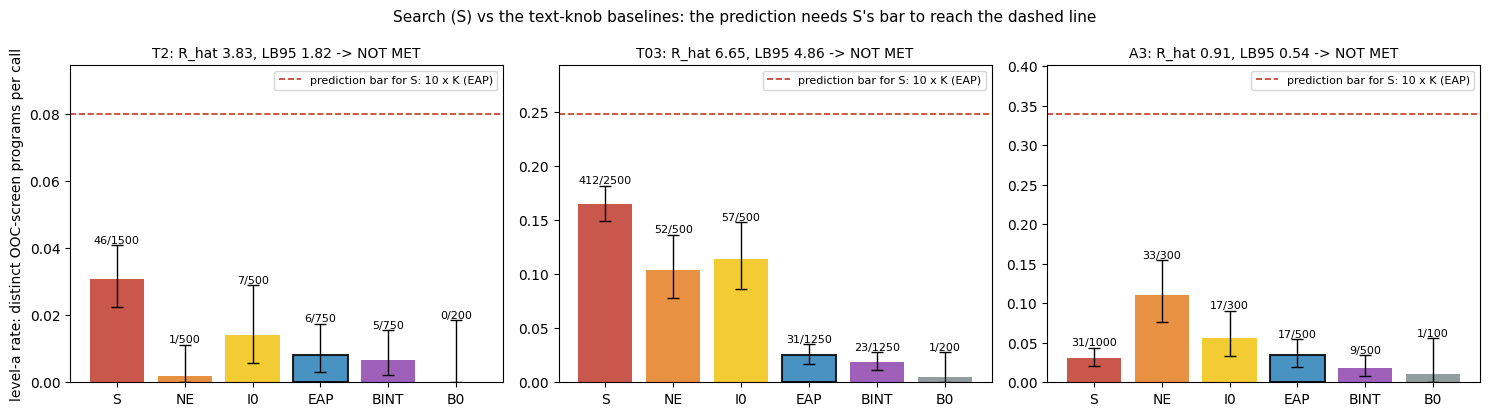

In [31]:
# Figure 1 - per-arm level-a rate (distinct OOC-screen programs per call) with Poisson 95% CIs; the dashed line is
# the pre-registered bar for S: 10x the rate of K (the better of EAP and BINT)
arm_colors = {"S": "#c0392b", "NE": "#e67e22", "I0": "#f1c40f", "EAP": "#2980b9", "BINT": "#8e44ad", "B0": "#7f8c8d"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, t in zip(axes, ("T2", "T03", "A3")):
    tab = TABLES["a"][t]
    k = rt["levels"]["a"]["per_task"][t]["K_arm"]
    for i, a in enumerate(ARMS):
        x, n = tab[a]["X_a"], tab[a]["N"]
        lo, hi = poisson_ci(x, n)
        ax.bar(i, x / n, color=arm_colors[a], alpha=0.85, edgecolor="black" if a == k else "none", linewidth=1.5)
        ax.errorbar(i, x / n, yerr=[[x / n - lo], [hi - x / n]], color="black", capsize=4, lw=1)
        ax.text(i, hi, f"{x}/{n}", ha="center", va="bottom", fontsize=8)
    bar = 10 * tab[k]["X_a"] / tab[k]["N"]
    ax.axhline(bar, ls="--", color="#c0392b", lw=1.2, label=f"prediction bar for S: 10 x K ({k})")
    ax.set_xticks(range(len(ARMS)), ARMS)
    test = rt["levels"]["a"]["per_task"][t]
    ax.set_title(f"{t}: R_hat {_f(test['R_hat'])}, LB95 {_f(test['LB95'])} -> {test['verdict']}", fontsize=10)
    ax.set_ylim(0, max(bar, max(poisson_ci(tab[a]['X_a'], tab[a]['N'])[1] for a in ARMS)) * 1.18)
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("level-a rate: distinct OOC-screen programs per call")
fig.suptitle("Search (S) vs the text-knob baselines: the prediction needs S's bar to reach the dashed line", fontsize=11)
plt.tight_layout()
plt.show()

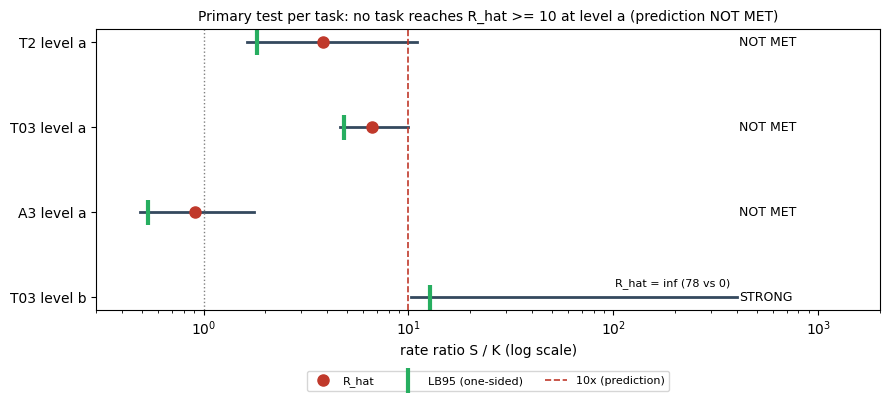

In [32]:
# Figure 2 - rate ratio R = rate_S / rate_K with the exact 95% CI and the one-sided LB95 (log scale);
# MET needs R_hat >= 10 with LB95 > 1, STRONG needs LB95 >= 10
fig, ax = plt.subplots(figsize=(9, 4.2))
rows_plot = [(f"{t} level a", rt["levels"]["a"]["per_task"][t]) for t in ("T2", "T03", "A3")]
rows_plot.append(("T03 level b", rt["levels"]["b"]["per_task"]["T03"]))
for y, (name, test) in enumerate(rows_plot):
    lo, hi = test["CI95"]
    hi_plot = hi if hi != math.inf else 400
    ax.plot([lo, hi_plot], [y, y], color="#34495e", lw=2)
    if test["R_hat"] != math.inf:
        ax.plot(test["R_hat"], y, "o", color="#c0392b", ms=8, label="R_hat" if y == 0 else None)
    else:
        ax.annotate("R_hat = inf (78 vs 0)", (hi_plot, y), xytext=(-5, 8), textcoords="offset points", ha="right", fontsize=8)
    ax.plot(test["LB95"], y, "|", color="#27ae60", ms=18, mew=3, label="LB95 (one-sided)" if y == 0 else None)
    ax.text(410, y, test["verdict"], va="center", fontsize=9)
ax.axvline(1, color="grey", ls=":", lw=1)
ax.axvline(10, color="#c0392b", ls="--", lw=1.2, label="10x (prediction)")
ax.set_xscale("log")
ax.set_xlim(0.3, 2000)
ax.set_yticks(range(len(rows_plot)), [n for n, _ in rows_plot])
ax.invert_yaxis()
ax.set_xlabel("rate ratio S / K (log scale)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.set_title("Primary test per task: no task reaches R_hat >= 10 at level a (prediction NOT MET)", fontsize=10)
plt.tight_layout()
plt.show()

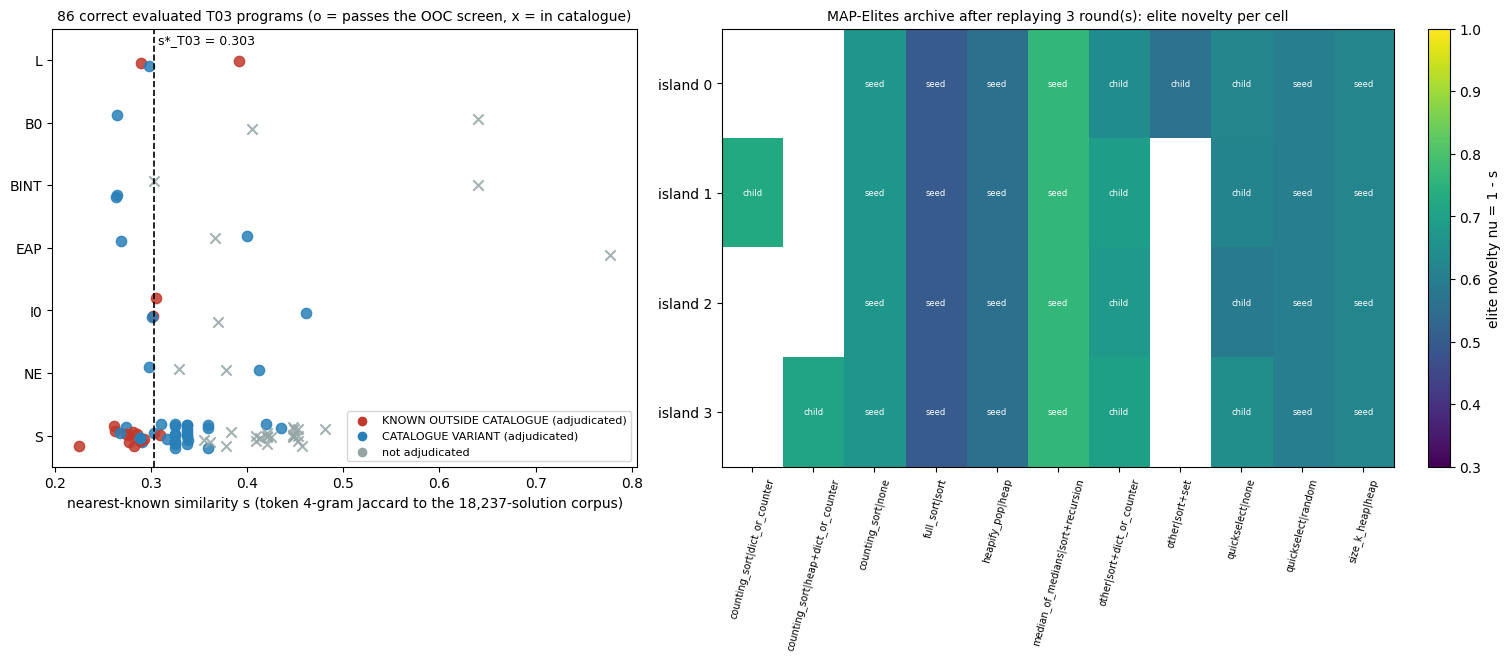

In [33]:
# Figure 3 - left: the OOC screen on the evaluated programs (nearest-known similarity s vs the screen threshold s*;
# a program is out of catalogue if s < s* or its label is 'other'); right: the archive cells the replay filled
cls_color = {"KNOWN OUTSIDE CATALOGUE": "#c0392b", "CATALOGUE VARIANT": "#2980b9", None: "#95a5a6"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.15]},
                               constrained_layout=True)
arm_order = ["S", "NE", "I0", "EAP", "BINT", "B0", "L"]
scored = df_eval[df_eval["s"].notna()]
for _, row in scored.iterrows():
    y = arm_order.index(row["arm"]) + (int(sha256_text(row["id"])[:4], 16) % 100 - 50) / 250   # stable jitter
    ax1.scatter(row["s"], y, s=55, color=cls_color.get(row["final class (run)"], "#95a5a6"),
                marker="o" if row["OOC screen"] else "x", alpha=0.85)
ax1.axvline(sstar["T03"], color="black", ls="--", lw=1.2)
ax1.text(sstar["T03"], 0.99, f" s*_T03 = {sstar['T03']:.3f}", fontsize=9, va="top", transform=ax1.get_xaxis_transform())
ax1.set_ylim(-0.5, len(arm_order) - 0.5)
ax1.set_yticks(range(len(arm_order)), arm_order)
ax1.set_xlabel("nearest-known similarity s (token 4-gram Jaccard to the 18,237-solution corpus)")
ax1.set_title(f"{len(scored)} correct evaluated T03 programs (o = passes the OOC screen, x = in catalogue)", fontsize=10)
for lab_, c in (("KNOWN OUTSIDE CATALOGUE (adjudicated)", "#c0392b"), ("CATALOGUE VARIANT (adjudicated)", "#2980b9"),
                ("not adjudicated", "#95a5a6")):
    ax1.scatter([], [], color=c, label=lab_)
ax1.legend(fontsize=8, loc="lower right")

all_cells = sorted({c for i in snap["islands"] for c in i["cells"]})
grid = np.full((len(snap["islands"]), len(all_cells)), np.nan)
for i in snap["islands"]:
    for c, e in i["cells"].items():
        grid[i["idx"], all_cells.index(c)] = e["novelty"]
im = ax2.imshow(grid, aspect="auto", cmap="viridis", vmin=0.3, vmax=1.0)
for i in snap["islands"]:
    for c, e in i["cells"].items():
        ax2.text(all_cells.index(c), i["idx"], "seed" if e["origin"] == "seed" else "child", ha="center", va="center",
                 fontsize=6, color="white")
ax2.set_xticks(range(len(all_cells)), all_cells, rotation=75, fontsize=7)
ax2.set_yticks(range(len(snap["islands"])), [f"island {i['idx']}" for i in snap["islands"]])
ax2.set_title(f"MAP-Elites archive after replaying {N_SEARCH_ROUNDS} round(s): elite novelty per cell", fontsize=10)
plt.colorbar(im, ax=ax2, label="elite novelty nu = 1 - s")
plt.show()

## Notes

- **Demo scale.** The config cell already uses everything the mini data holds: all 100 programs, three replayed rounds, and the run's 2,000 bootstrap replicates, which match the published interval exactly. Lower the values to run a faster partial check.
- **Running the full method.** The full run needs:
  - the artifact repository and its `method.py` stage CLI;
  - a 20 GB GPU for the vLLM stages, about 1 GPU-hour;
  - an OpenRouter key for the judges and arm L, USD 0.89 in total;
  - the declared corpus dependency `art_j3Rm_lr2nzR6`.

  `reproducibility.md` in the artifact lists every command.
- **Deliberately not re-run:**
  - **Generation:** replayed from recorded children.
  - **Runtime/AST labellers:** recorded labels, looked up by sha256.
  - **Adjudication:** recorded manual reads and judge answers. The pre-registered judge gate failed (best judge 8/10 controls), so final classes are the executor's manual reads of all 244 candidates.